# Accuracy–Latency Pareto
This notebook preserves the supplied accuracy/latency values and Pareto objective, while matching the ReportLab layout/theme of the ECE–NLL figure. Latency is shown on a log scale; upper-left is preferred (lower latency, higher accuracy).

Saved 10 panels with 65 available accuracy/latency pairs to figures


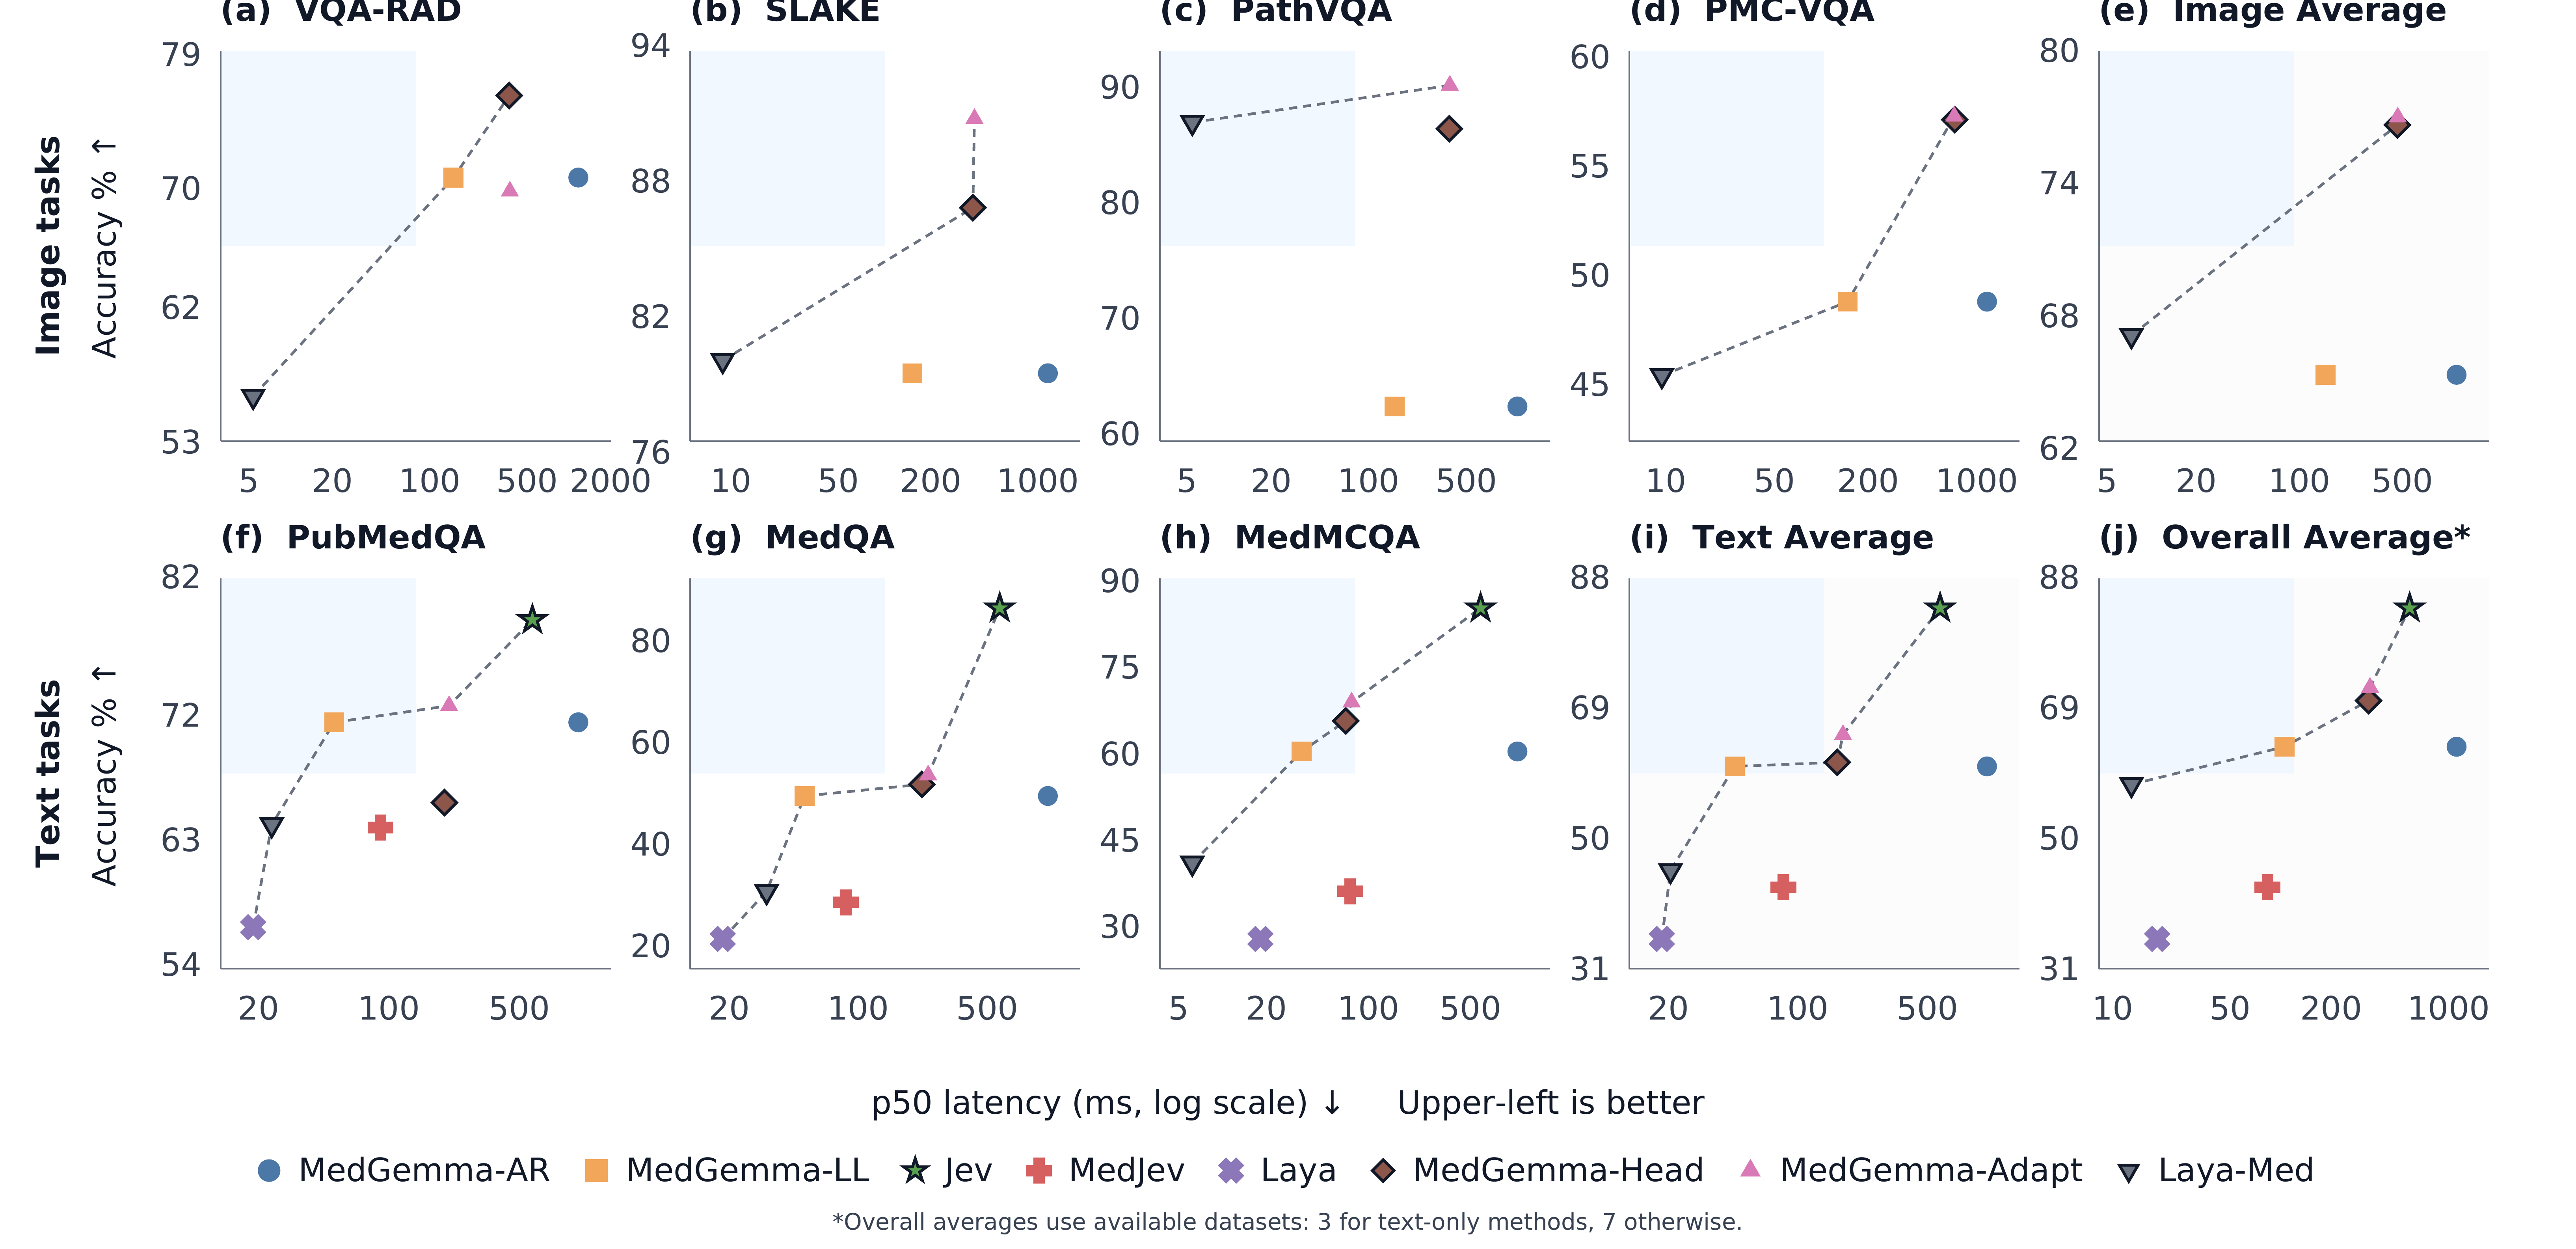

In [42]:
# Install once if needed:
# %pip install reportlab
from pathlib import Path
OUTDIR = Path('figures')
FONT_DIR = None

from pathlib import Path
import csv, importlib.util, shutil, subprocess, math
from reportlab.graphics.shapes import Drawing, Group, String, Rect, PolyLine
from reportlab.graphics.charts.lineplots import LinePlot
from reportlab.graphics.widgets.markers import makeMarker
from reportlab.graphics import renderPDF, renderSVG
from reportlab.lib.colors import HexColor, Color
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont

METHODS = ['MedGemma-AR', 'MedGemma-LL', 'Jev', 'MedJev', 'Laya', 'MedGemma-Head', 'MedGemma-Adapt', 'Laya-Med']
# Read measured results; the rendering code below is unchanged.
import sys
_results_root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "analysis" / "notebook_results.py").is_file()
)
if str(_results_root / "analysis") not in sys.path:
    sys.path.insert(0, str(_results_root / "analysis"))
from notebook_results import load_paper_results
_saved_results = load_paper_results()
ACCURACY = _saved_results["accuracy"]
LATENCY = _saved_results["latency"]
DATASETS = ['VQA-RAD','SLAKE','PathVQA','PMC-VQA','Image Average','PubMedQA','MedQA','MedMCQA','Text Average','Overall Average']

def locate_fonts(explicit=None):
    candidates = [Path(explicit)] if explicit else []
    candidates += [Path('/usr/share/fonts/truetype/dejavu'), Path('/usr/share/fonts/dejavu'), Path('/usr/local/share/fonts'), Path.home()/'.fonts', Path.home()/'Library/Fonts']
    spec=importlib.util.find_spec('matplotlib')
    if spec and spec.origin: candidates.append(Path(spec.origin).parent/'mpl-data/fonts/ttf')
    for folder in candidates:
        if all((folder/f).exists() for f in ['DejaVuSans.ttf','DejaVuSans-Bold.ttf']): return folder
    raise RuntimeError('DejaVu Sans not found; set FONT_DIR.')

def pareto(points):
    out=[]
    for i,p in enumerate(points):
        _,lat,acc=p
        dominated=any(j!=i and q[1]<=lat and q[2]>=acc and (q[1]<lat or q[2]>acc) for j,q in enumerate(points))
        if not dominated: out.append(p)
    return sorted(out,key=lambda z:z[1])

def generate(outdir=OUTDIR, font_dir=FONT_DIR, make_png=True):
    outdir=Path(outdir); outdir.mkdir(parents=True,exist_ok=True)
    fd=locate_fonts(font_dir)
    for name,fn in [('DejaVuSans','DejaVuSans.ttf'),('DejaVuSans-Bold','DejaVuSans-Bold.ttf')]:
        try: pdfmetrics.registerFont(TTFont(name,str(fd/fn)))
        except: pass
    colors=['#4C78A8','#F2A65A','#59A14F','#D65F5F','#8C78B8','#8C564B','#D979B5','#6B7280']
    kinds=['FilledCircle','FilledSquare','FilledStarFive','Cross','Cross','FilledDiamond','FilledTriangle','FilledTriangle']
    angles=[0,0,0,0,45,0,0,180]
    ink=HexColor('#111827'); gray=HexColor('#374151'); spine=HexColor('#6B7280')
    W,H=957.267906,463.868812; d=Drawing(W,H)
    def txt(x,y,t,size=12,bold=False,align='start',color=ink):
        d.add(String(x,y,t,fontName='DejaVuSans-Bold' if bold else 'DejaVuSans',fontSize=size,fillColor=color,textAnchor=align))
    def marker(j,size=None):
        m=makeMarker(kinds[j]); m.size=size or [7,7,10,8,8,9,7,9][j]; m.angle=angles[j]
        m.fillColor=HexColor(colors[j]); m.strokeColor=ink if j in (2,5,7) else HexColor(colors[j]); m.strokeWidth=1.05 if j in (2,5,7) else (1.6 if j in (3,4) else .4); return m
    rows=[]; placements=[]
    for ds in DATASETS:
        for m in METHODS:
            a=ACCURACY[ds].get(m); l=LATENCY[ds].get(m)
            rows.append(dict(dataset=ds,method=m,accuracy=a,latency=l))
    for i,name in enumerate(DATASETS):
        col=i%5; row=i//5; x=82+col*174.5; y=300 if row==0 else 104; w=145; h=145
        if 'Average' in name: d.add(Rect(x,y,w,h,fillColor=HexColor('#FCFCFD'),strokeColor=None))
        pts=[(m,float(LATENCY[name][m]),float(ACCURACY[name][m])) for m in METHODS if ACCURACY[name].get(m) is not None and LATENCY[name].get(m) is not None]
        logs=[math.log10(p[1]) for p in pts]; ys=[p[2] for p in pts]
        xmin,xmax=min(logs),max(logs); padx=max(.12,(xmax-xmin)*.10); xmin-=padx; xmax+=padx
        ymin,ymax=min(ys),max(ys); pady=max(3,(ymax-ymin)*.09); ymin=max(0,ymin-pady); ymax=min(100,ymax+pady)
        if ymax-ymin<16: c=(ymax+ymin)/2; ymin=max(0,c-8); ymax=min(100,c+8)
        # Same pale-blue cue as ECE-NLL, adapted to the desired upper-left direction.
        d.add(Rect(x,y+h/2,w/2,h/2,fillColor=Color(238/255,246/255,1,alpha=.75),strokeColor=None))
        # Pareto frontier in the same restrained gray dashed visual language.
        fr=pareto(pts)
        if len(fr)>=2:
            xy=[]
            for _,lat,acc in fr:
                px=x+(math.log10(lat)-xmin)/(xmax-xmin)*w; py=y+(acc-ymin)/(ymax-ymin)*h; xy += [px,py]
            pl=PolyLine(xy,strokeColor=spine,strokeWidth=1.0); pl.strokeDashArray=[3,2.2]; d.add(pl)
        plot=LinePlot(); plot.x=x; plot.y=y; plot.width=w; plot.height=h
        inds=[]; data=[]
        for j,m in enumerate(METHODS):
            a=ACCURACY[name].get(m); lat=LATENCY[name].get(m)
            if a is None or lat is None: continue
            inds.append(j); lx=math.log10(lat); data.append([(lx,a)])
            placements.append(dict(dataset=name,method=m,accuracy=a,latency=lat))
        plot.data=data
        for k,j in enumerate(inds): plot.lines[k].strokeColor=None; plot.lines[k].strokeWidth=0; plot.lines[k].symbol=marker(j)
        # x ticks at clean latency values inside each panel range
        cand=[5,10,20,50,100,200,500,1000,2000]
        xt=[math.log10(v) for v in cand if xmin<=math.log10(v)<=xmax]
        if len(xt)>4: xt=xt[::2]
        # yt0=math.ceil(ymin/10)*10; yt1=math.floor(ymax/10)*10; yt=list(range(int(yt0),int(yt1)+1,10)) or [round(ymin),round(ymax)]
        # ------------------------------------------------------------
        # Y ticks: minimum 4, maximum 6 labels per subplot
        # ------------------------------------------------------------

        span = ymax - ymin

        # Choose a clean step based on the visible y-range
        if span <= 20:
            ystep = 5
        elif span <= 35:
            ystep = 10
        elif span <= 55:
            ystep = 10
        elif span <= 75:
            ystep = 15
        else:
            ystep = 20

        yt0 = math.ceil(ymin / ystep) * ystep
        yt1 = math.floor(ymax / ystep) * ystep

        yt = []
        v = yt0

        while v <= yt1 + 1e-9:
            yt.append(v)
            v += ystep

        # If fewer than 4 ticks, generate 4 evenly spaced ticks
        if len(yt) < 4:
            yt = [
                ymin + i * (ymax - ymin) / 3
                for i in range(4)
            ]

            # Round to clean integer values
            yt = [round(v) for v in yt]

        # If more than 6 ticks, reduce to 6
        if len(yt) > 6:
            indices = [
                round(i * (len(yt) - 1) / 5)
                for i in range(6)
            ]
            yt = [yt[i] for i in indices]
        plot.xValueAxis.valueMin=xmin; plot.xValueAxis.valueMax=xmax; plot.xValueAxis.valueSteps=xt; plot.xValueAxis.forceZero=False
        plot.yValueAxis.valueMin=ymin; plot.yValueAxis.valueMax=ymax; plot.yValueAxis.valueSteps=yt; plot.yValueAxis.forceZero=False
        for axis in (plot.xValueAxis,plot.yValueAxis):
            axis.visibleGrid=False; axis.strokeColor=spine; axis.strokeWidth=.6; axis.visibleTicks=False; axis.labels.fontName='DejaVuSans'; axis.labels.fontSize=12; axis.labels.fillColor=gray
        plot.xValueAxis.labelTextFormat=lambda v: f'{10**v:g}'; plot.yValueAxis.labelTextFormat=lambda v:f'{v:g}'
        plot.xValueAxis.labels.dy=-7; plot.xValueAxis.labels.boxAnchor='n'; plot.yValueAxis.labels.dx=-7; plot.yValueAxis.labels.boxAnchor='e'
        plot.xValueAxis.joinAxisMode='bottom'; plot.yValueAxis.joinAxisMode='left'; d.add(plot)
        title=name+('*' if name=='Overall Average' else '')
        txt(x,y+h+11,f'({chr(97+i)})  {title}',12,True)
    for label,cy in [('Image tasks',372.5),('Text tasks',176.5)]:
        g=Group(); g.add(String(0,0,label,fontName='DejaVuSans-Bold',fontSize=12,fillColor=ink,textAnchor='middle')); g.translate(22,cy); g.rotate(90); d.add(g)
        g=Group(); g.add(String(0,0,'Accuracy % ↑',fontName='DejaVuSans',fontSize=12,fillColor=ink,textAnchor='middle')); g.translate(43,cy); g.rotate(90); d.add(g)
    txt(W/2,50,'p50 latency (ms, log scale) ↓     Upper-left is better',12,align='middle')
    widths=[16+pdfmetrics.stringWidth(m,'DejaVuSans',12)+12 for m in METHODS]; xx=(W-sum(widths)+12)/2
    for j,m in enumerate(METHODS):
        q=marker(j,8 if j!=2 else 9); q.x=xx+4; q.y=29; d.add(q); txt(xx+15,25,m,12); xx+=widths[j]
    txt(W/2,7,'*Overall averages use available datasets: 3 for text-only methods, 7 otherwise.',8.5,align='middle',color=gray)
    assert len(placements)==65
    stem=outdir/'accuracy_latency_pareto_ece_nll_style'
    # Uniform physical scaling: 4.5 x 4.5 inches per data panel.
    panel_scale = (4.5 * 72) / 145
    d.scale(panel_scale, panel_scale)
    d.width *= panel_scale
    d.height *= panel_scale
    renderPDF.drawToFile(d,str(stem.with_suffix('.pdf')),title='Accuracy-latency Pareto quality')
    renderSVG.drawToFile(d,str(stem.with_suffix('.svg')))
    with (outdir/'accuracy_latency_pareto_ece_nll_style_data.csv').open('w',newline='') as f:
        wr=csv.DictWriter(f,fieldnames=['dataset','method','accuracy','latency']); wr.writeheader(); wr.writerows(rows)
    if make_png:
        poppler=shutil.which('pdftoppm')
        if poppler: subprocess.run([poppler,'-r','220','-png','-singlefile',str(stem.with_suffix('.pdf')),str(stem)],check=True)
    print(f'Saved 10 panels with {len(placements)} available accuracy/latency pairs to {outdir}')
    return stem

stem = generate()

from IPython.display import Image, display
png = stem.with_suffix('.png')
if png.exists(): display(Image(filename=str(png)))
else: print('PNG not available; PDF/SVG were still created.')

# Heatmap Table for Tex

In [43]:
#!/usr/bin/env python3
"""
Generate the Medical SysOne benchmark table as TikZ.

Each method x dataset cell contains:
    top    : Accuracy (%)     [red -> green; higher = better]
    bottom : p50 latency (ms) [red -> green; lower = better;
                               lighter tint + smaller gray text]

Unavailable evaluations are shown as "n/s".

Output
------
medical_sysone_table.tex

Usage
-----
python generate_sysone_table.py

Then include in LaTeX with:
    \\input{medical_sysone_table.tex}

Required LaTeX packages:
    \\usepackage{tikz}
    \\usepackage{xcolor}
    \\usepackage{fontawesome5}
"""

from __future__ import annotations

from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple


# ============================================================
# Configuration
# ============================================================

OUTPUT = Path("medical_sysone_table.tex")


# ============================================================
# Methods
# ============================================================

METHODS = [
    "MedGemma-AR",
    "MedGemma-LL",
    "Jev",
    "MedJev",
    "Laya",
    "MedGemma-Head",
    "MedGemma-Adapt",
    "Laya-Med",
]


METHOD_DISPLAY = {
    "MedGemma-AR": r"MedGemma\\AR",
    "MedGemma-LL": r"MedGemma\\LL",
    "Jev": "Jev",
    "MedJev": "MedJev",
    "Laya": "Laya",
    "MedGemma-Head": r"MedGemma\\Head",
    "MedGemma-Adapt": r"MedGemma\\Adapt",
    "Laya-Med": "Laya-Med",
}


# ============================================================
# Dataset groups
# ============================================================

GROUPS = [
    (
        "Text Medical QA",
        [
            "PubMedQA",
            "MedQA",
            "MedMCQA",
            "Text Average",
        ],
    ),
    (
        "Medical VQA",
        [
            "VQA-RAD",
            "SLAKE",
            "PathVQA",
            "PMC-VQA",
            "Image Average",
        ],
    ),
    (
        "Overall",
        [
            "Overall Average",
        ],
    ),
]


# ============================================================
# Accuracy (%)
# ============================================================

# Read measured results; the rendering code below is unchanged.
import sys
_results_root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "analysis" / "notebook_results.py").is_file()
)
if str(_results_root / "analysis") not in sys.path:
    sys.path.insert(0, str(_results_root / "analysis"))
from notebook_results import load_paper_results
_saved_results = load_paper_results()
ACCURACY = {dataset: [values[method] for method in METHODS]
            for dataset, values in _saved_results["accuracy"].items()}


# ============================================================
# p50 latency (ms)
# ============================================================

LATENCY = {dataset: [values[method] for method in METHODS]
            for dataset, values in _saved_results["latency"].items()}


# ============================================================
# Layout
# ============================================================

GROUP_X0 = 0.00
GROUP_W = 2.45

DATASET_X0 = 2.55
DATASET_W = 2.35

METHOD_X0 = 5.05

METHOD_W = 1.27
METHOD_GAP = 0.08

HEADER_H = 1.20

ROW_H = 0.73
GROUP_GAP = 0.16

# Each method cell contains two stacked mini-cells.
CELL_W = 1.16
CELL_H = 0.27
CELL_GAP = 0.055

BOTTOM_LEGEND_GAP = 0.55


# ============================================================
# Group colors
# ============================================================

GROUP_COLORS = {
    "Text Medical QA": "blue",
    "Medical VQA": "teal",
    "Overall": "violet",
}


# ============================================================
# Performance palette
#
# Same semantic palette for both metrics:
#
#   red    = worse
#   yellow = intermediate
#   green  = better
#
# Accuracy:
#   higher -> greener
#
# Latency:
#   lower -> greener
# ============================================================

ACC_COLORS = [
    (248, 194, 187),   # worst
    (249, 207, 183),
    (250, 224, 181),
    (244, 236, 184),
    (218, 235, 185),
    (181, 225, 181),
    (139, 211, 174),   # best
]


# ============================================================
# Helpers
# ============================================================

def escape_tex(text: str) -> str:
    """Minimal TeX escaping for generated labels."""

    return (
        text
        .replace("&", r"\&")
        .replace("%", r"\%")
        .replace("_", r"\_")
    )


def lighten_rgb(
    rgb: Tuple[int, int, int],
    amount: float = 0.35,
) -> Tuple[int, int, int]:
    """
    Blend an RGB color toward white.

    amount = 0 -> original
    amount = 1 -> white
    """

    return tuple(
        round(
            channel
            + (255 - channel) * amount
        )
        for channel in rgb
    )


def interpolate_rgb(
    palette: Sequence[Tuple[int, int, int]],
    t: float,
) -> Tuple[int, int, int]:
    """
    Piecewise-linear interpolation through an RGB palette.

    Parameters
    ----------
    palette
        Ordered RGB colors from worst to best.

    t
        Scalar in [0, 1].
    """

    t = max(
        0.0,
        min(1.0, t),
    )

    if len(palette) == 1:
        return palette[0]

    position = (
        t
        * (len(palette) - 1)
    )

    index = int(position)

    if index >= len(palette) - 1:
        return palette[-1]

    fraction = position - index

    first = palette[index]
    second = palette[index + 1]

    return tuple(
        round(
            first[channel]
            + fraction
            * (
                second[channel]
                - first[channel]
            )
        )
        for channel in range(3)
    )


def rgb_tex(
    rgb: Tuple[int, int, int],
) -> str:
    """Convert RGB tuple to xcolor/TikZ inline RGB syntax."""

    r, g, b = rgb

    return (
        f"{{rgb,255:red,{r};"
        f"green,{g};"
        f"blue,{b}}}"
    )


def normalize(
    value: float,
    lo: float,
    hi: float,
) -> float:
    """Normalize to [0,1]."""

    if hi == lo:
        return 0.5

    return (
        (value - lo)
        / (hi - lo)
    )


def valid_values(
    values: Sequence[Optional[float]],
) -> List[float]:
    """Return all non-missing numeric values."""

    return [
        float(value)
        for value in values
        if value is not None
    ]


def best_indices(
    values: Sequence[Optional[float]],
    higher_is_better: bool,
) -> set[int]:
    """
    Return all indices tied for the best available value.
    """

    valid = valid_values(values)

    if not valid:
        return set()

    if higher_is_better:
        target = max(valid)
    else:
        target = min(valid)

    return {
        index
        for index, value in enumerate(values)
        if (
            value is not None
            and abs(
                float(value)
                - target
            ) < 1e-9
        )
    }


def format_accuracy(
    value: float,
) -> str:
    """Accuracy is always shown with one decimal place."""

    return f"{value:.1f}"


def format_latency(
    value: float,
) -> str:
    """Latency is shown as integer milliseconds."""

    return f"{value:.0f}"


def method_x(
    index: int,
) -> float:
    """Horizontal center of a method column."""

    return (
        METHOD_X0
        + index
        * (
            METHOD_W
            + METHOD_GAP
        )
        + METHOD_W / 2
    )


def row_center(
    y_top: float,
) -> float:
    """Vertical center of a dataset row."""

    return (
        y_top
        - ROW_H / 2
    )


# ============================================================
# TikZ heatmap cell
# ============================================================

def heat_cell(
    x: float,
    y: float,
    value: Optional[float],
    color_value: Optional[float],
    color_values: Sequence[Optional[float]],
    metric: str,
    bold: bool = False,
) -> str:
    """
    Generate one rounded TikZ heatmap mini-cell.

    Accuracy
    --------
    Higher values -> greener.

    Latency
    -------
    Lower values -> greener.
    Latency cells are lightened and use smaller gray text.
    """

    # --------------------------------------------------------
    # Unsupported / unavailable
    # --------------------------------------------------------

    if value is None:

        return (
            rf"\node["
            rf"fill=gray!12,"
            rf"rounded corners=2pt,"
            rf"minimum width={CELL_W:.3f}cm,"
            rf"minimum height={CELL_H:.3f}cm,"
            rf"inner sep=0pt,"
            rf"text=gray!55"
            rf"] "
            rf"at ({x:.3f},{y:.3f}) "
            rf"{{n/s}};"
        )

    # --------------------------------------------------------
    # Row-wise normalization
    # --------------------------------------------------------

    valid = valid_values(
        color_values
    )

    lo = min(valid)
    hi = max(valid)

    if metric == "accuracy":

        # Higher accuracy = better.
        score = normalize(
            float(color_value),
            lo,
            hi,
        )

    elif metric == "latency":

        # Lower latency = better.
        score = (
            1.0
            - normalize(
                float(color_value),
                lo,
                hi,
            )
        )

    else:

        raise ValueError(
            f"Unknown metric: {metric}"
        )

    # --------------------------------------------------------
    # Map quality -> color
    # --------------------------------------------------------

    rgb = interpolate_rgb(
        ACC_COLORS,
        score,
    )

    # Latency uses same semantics,
    # but is visually secondary.
    # if metric == "latency":

    #     rgb = lighten_rgb(
    #         rgb,
    #         amount=0.35,
    #     )

    # --------------------------------------------------------
    # Text formatting
    # --------------------------------------------------------

    if metric == "accuracy":

        text = format_accuracy(
            float(value)
        )

        if bold:
            text = (
                rf"\textbf{{{text}}}"
            )

        text_style = (
            r"text=black,"
            r"font=\scriptsize"
        )

    else:

        text = format_latency(
            float(value)
        )

        if bold:
            text = (
                rf"\textbf{{{text}}}"
            )

        text_style = (
            r"text=gray!65!black,"
            r"font=\tiny"
        )

    # --------------------------------------------------------
    # Node
    # --------------------------------------------------------

    return (
        rf"\node["
        rf"fill={rgb_tex(rgb)},"
        rf"rounded corners=2pt,"
        rf"minimum width={CELL_W:.3f}cm,"
        rf"minimum height={CELL_H:.3f}cm,"
        rf"inner sep=0pt,"
        rf"{text_style}"
        rf"] "
        rf"at ({x:.3f},{y:.3f}) "
        rf"{{{text}}};"
    )


# ============================================================
# Build TikZ
# ============================================================

def build_tikz() -> str:

    lines: List[str] = []

    # ========================================================
    # Begin figure
    # ========================================================

    lines.append(
        r"\begin{tikzpicture}[x=1cm,y=1cm,font=\scriptsize]"
    )

    # ========================================================
    # Header labels
    # ========================================================

    lines.append(
        rf"\node["
        rf"font=\sffamily\bfseries\small,"
        rf"anchor=west"
        rf"] "
        rf"at ({GROUP_X0 + 0.10:.3f},-0.72) "
        rf"{{Task Group}};"
    )

    lines.append(
        rf"\node["
        rf"font=\sffamily\bfseries\small,"
        rf"anchor=west"
        rf"] "
        rf"at ({DATASET_X0 + 0.08:.3f},-0.72) "
        rf"{{Dataset}};"
    )

    # ========================================================
    # Method headers
    # ========================================================

    for index, method in enumerate(
        METHODS
    ):

        x = method_x(index)

        # Last three = controlled configurations.
        if index >= 5:
            header_fill = "violet!10"
        else:
            header_fill = "gray!9"

        # Header background.
        lines.append(
            rf"\fill["
            rf"{header_fill},"
            rf"rounded corners=3pt"
            rf"] "
            rf"({x - METHOD_W/2:.3f},0) "
            rf"rectangle "
            rf"({x + METHOD_W/2:.3f},"
            rf"-{HEADER_H:.3f});"
        )

        # Method name.
        lines.append(
            rf"\node["
            rf"align=center,"
            rf"font=\sffamily\tiny\bfseries"
            rf"] "
            rf"at ({x:.3f},-0.47) "
            rf"{{{METHOD_DISPLAY[method]}}};"
        )

        # Metric labels.
        lines.append(
            rf"\node["
            rf"align=center,"
            rf"font=\tiny,"
            rf"text=gray!70!black"
            rf"] "
            rf"at ({x:.3f},-0.93) "
            rf"{{Acc.\\p50}};"
        )

    # ========================================================
    # Controlled-configuration divider
    # ========================================================

    divider_x = (
        method_x(4)
        + method_x(5)
    ) / 2

    # We don't know final bottom coordinate yet.
    divider_line_index = len(lines)

    lines.append(
        "__DIVIDER__"
    )

    # ========================================================
    # Dataset rows
    # ========================================================

    y_top = (
        -HEADER_H
        - 0.18
    )

    for (
        group_name,
        datasets,
    ) in GROUPS:

        group_start_y = y_top

        group_height = (
            len(datasets)
            * ROW_H
        )

        group_color = (
            GROUP_COLORS[
                group_name
            ]
        )

        # ----------------------------------------------------
        # Task-group background
        # ----------------------------------------------------

        lines.append(
            rf"\fill["
            rf"{group_color}!13,"
            rf"rounded corners=3pt"
            rf"] "
            rf"({GROUP_X0:.3f},"
            rf"{group_start_y:.3f}) "
            rf"rectangle "
            rf"({GROUP_X0 + GROUP_W:.3f},"
            rf"{group_start_y - group_height:.3f});"
        )

        # ----------------------------------------------------
        # Dataset-name background
        # ----------------------------------------------------

        lines.append(
            rf"\fill["
            rf"{group_color}!8,"
            rf"rounded corners=3pt"
            rf"] "
            rf"({DATASET_X0:.3f},"
            rf"{group_start_y:.3f}) "
            rf"rectangle "
            rf"({DATASET_X0 + DATASET_W:.3f},"
            rf"{group_start_y - group_height:.3f});"
        )

        # ----------------------------------------------------
        # Group title / icon
        # ----------------------------------------------------

        group_y = (
            group_start_y
            - group_height / 2
        )

        if group_name == "Text Medical QA":

            group_content = (
                r"{\Large\faFileMedical}\\[3pt]"
                r"Text Medical QA"
            )

        elif group_name == "Medical VQA":

            group_content = (
                r"{\Large\faMicroscope}\\[3pt]"
                r"Medical VQA"
            )

        else:

            # Overall row is too short for a stacked icon.
            group_content = (
                r"Overall"
            )

        lines.append(
            rf"\node["
            rf"align=center,"
            rf"text width={GROUP_W - 0.25:.2f}cm,"
            rf"font=\sffamily\scriptsize\bfseries,"
            rf"text={group_color}!55!black"
            rf"] "
            rf"at ("
            rf"{GROUP_X0 + GROUP_W/2:.3f},"
            rf"{group_y:.3f}"
            rf") "
            rf"{{{group_content}}};"
        )

        # ====================================================
        # Individual datasets
        # ====================================================

        for dataset in datasets:

            yc = row_center(
                y_top
            )

            is_average = (
                "Average"
                in dataset
            )

            dataset_text = (
                escape_tex(dataset)
            )

            if is_average:

                dataset_text = (
                    rf"\textbf{{"
                    rf"{dataset_text}"
                    rf"}}"
                )

            # Dataset label.
            lines.append(
                rf"\node["
                rf"anchor=west,"
                rf"font=\scriptsize"
                rf"] "
                rf"at ("
                rf"{DATASET_X0 + 0.12:.3f},"
                rf"{yc:.3f}"
                rf") "
                rf"{{{dataset_text}}};"
            )

            # ------------------------------------------------
            # Values
            # ------------------------------------------------

            acc_values = (
                ACCURACY[dataset]
            )

            lat_values = (
                LATENCY[dataset]
            )

            best_acc = (
                best_indices(
                    acc_values,
                    higher_is_better=True,
                )
            )

            best_lat = (
                best_indices(
                    lat_values,
                    higher_is_better=False,
                )
            )

            # ------------------------------------------------
            # Method cells
            # ------------------------------------------------

            for index, method in enumerate(
                METHODS
            ):

                x = method_x(
                    index
                )

                acc_y = (
                    yc
                    + (
                        CELL_H
                        + CELL_GAP
                    )
                    / 2
                )

                lat_y = (
                    yc
                    - (
                        CELL_H
                        + CELL_GAP
                    )
                    / 2
                )

                # Accuracy cell.
                lines.append(
                    heat_cell(
                        x=x,
                        y=acc_y,

                        value=(
                            acc_values[
                                index
                            ]
                        ),

                        color_value=(
                            acc_values[
                                index
                            ]
                        ),

                        color_values=(
                            acc_values
                        ),

                        metric="accuracy",

                        bold=(
                            index
                            in best_acc
                        ),
                    )
                )

                # Latency cell.
                lines.append(
                    heat_cell(
                        x=x,
                        y=lat_y,

                        value=(
                            lat_values[
                                index
                            ]
                        ),

                        color_value=(
                            lat_values[
                                index
                            ]
                        ),

                        color_values=(
                            lat_values
                        ),

                        metric="latency",

                        bold=(
                            index
                            in best_lat
                        ),
                    )
                )

            # ------------------------------------------------
            # Average separator
            # ------------------------------------------------

            if is_average:

                x_end = (
                    method_x(
                        len(METHODS) - 1
                    )
                    + METHOD_W / 2
                )

                lines.append(
                    rf"\draw["
                    rf"gray!40,"
                    rf"line width=0.35pt"
                    rf"] "
                    rf"({DATASET_X0:.3f},"
                    rf"{y_top:.3f}) -- "
                    rf"({x_end:.3f},"
                    rf"{y_top:.3f});"
                )

            y_top -= ROW_H

        # Space between task groups.
        y_top -= GROUP_GAP

    # ========================================================
    # Finish controlled divider
    # ========================================================

    final_table_y = (
        y_top
        + GROUP_GAP
    )

    lines[
        divider_line_index
    ] = (
        rf"\draw["
        rf"gray!60,"
        rf"dashed,"
        rf"line width=0.45pt"
        rf"] "
        rf"({divider_x:.3f},0) -- "
        rf"({divider_x:.3f},"
        rf"{final_table_y:.3f});"
    )

    # ========================================================
    # Controlled configurations annotation
    # ========================================================

    ours_center = (
        method_x(5)
        + method_x(7)
    ) / 2

    lines.append(
        rf"\node["
        rf"font=\tiny\itshape,"
        rf"text=gray!70!black"
        rf"] "
        rf"at ({ours_center:.3f},0.18) "
        rf"{{Controlled configurations}};"
    )

    # ========================================================
    # Bottom legend
    # ========================================================

    legend_y = (
        final_table_y
        - BOTTOM_LEGEND_GAP
    )

    # --------------------------------------------------------
    # Worst label
    # --------------------------------------------------------

    worst_x = 3.50

    lines.append(
        rf"\node["
        rf"anchor=west,"
        rf"font=\sffamily\scriptsize"
        rf"] "
        rf"at ({worst_x:.3f},"
        rf"{legend_y:.3f}) "
        rf"{{Worst}};"
    )

    # --------------------------------------------------------
    # Performance color scale
    # --------------------------------------------------------

    current_x = 4.55

    box_w = 0.42
    box_gap = 0.08

    for color in ACC_COLORS:

        r, g, b = color

        lines.append(
            rf"\fill["
            rf"fill={{rgb,255:"
            rf"red,{r};"
            rf"green,{g};"
            rf"blue,{b}}},"
            rf"rounded corners=1.5pt"
            rf"] "
            rf"({current_x:.3f},"
            rf"{legend_y - 0.15:.3f}) "
            rf"rectangle "
            rf"({current_x + box_w:.3f},"
            rf"{legend_y + 0.15:.3f});"
        )

        current_x += (
            box_w
            + box_gap
        )

    # --------------------------------------------------------
    # Best label
    # --------------------------------------------------------

    lines.append(
        rf"\node["
        rf"anchor=west,"
        rf"font=\sffamily\scriptsize"
        rf"] "
        rf"at (8.100,"
        rf"{legend_y:.3f}) "
        rf"{{Best}};"
    )

    # --------------------------------------------------------
    # Not-supported key
    # --------------------------------------------------------

    na_x = 10.950

    lines.append(
        rf"\node["
        rf"fill=gray!12,"
        rf"rounded corners=2pt,"
        rf"minimum width=0.48cm,"
        rf"minimum height=0.30cm,"
        rf"inner sep=0pt,"
        rf"text=gray!55"
        rf"] "
        rf"at ({na_x:.3f},"
        rf"{legend_y:.3f}) "
        rf"{{n/s}};"
    )

    lines.append(
        rf"\node["
        rf"anchor=west,"
        rf"font=\sffamily\scriptsize,"
        rf"text=black"
        rf"] "
        rf"at ({na_x + 0.38:.3f},"
        rf"{legend_y:.3f}) "
        rf"{{not supported}};"
    )

    # ========================================================
    # End TikZ
    # ========================================================

    lines.append(
        r"\end{tikzpicture}"
    )

    return "\n".join(
        lines
    )


# ============================================================
# Validation
# ============================================================

def validate_data() -> None:
    """
    Validate that every dataset contains one value per method.
    """

    expected = len(
        METHODS
    )

    datasets = [
        dataset
        for _, group_datasets in GROUPS
        for dataset in group_datasets
    ]

    for dataset in datasets:

        if dataset not in ACCURACY:

            raise KeyError(
                f"Missing accuracy data: "
                f"{dataset}"
            )

        if dataset not in LATENCY:

            raise KeyError(
                f"Missing latency data: "
                f"{dataset}"
            )

        if (
            len(
                ACCURACY[
                    dataset
                ]
            )
            != expected
        ):

            raise ValueError(
                f"{dataset}: "
                f"accuracy has "
                f"{len(ACCURACY[dataset])} "
                f"values; "
                f"expected {expected}"
            )

        if (
            len(
                LATENCY[
                    dataset
                ]
            )
            != expected
        ):

            raise ValueError(
                f"{dataset}: "
                f"latency has "
                f"{len(LATENCY[dataset])} "
                f"values; "
                f"expected {expected}"
            )


# ============================================================
# Main
# ============================================================

def main() -> None:

    validate_data()

    tikz = build_tikz()

    OUTPUT.write_text(
        tikz,
        encoding="utf-8",
    )

    print(
        f"Wrote: "
        f"{OUTPUT.resolve()}"
    )


if __name__ == "__main__":
    main()

Wrote: /home/razaimam/Documents/Projects/Jevify/analysis/medical_sysone_table.tex


# Probabilistic Decision Quality - ECE/NLL
Notebook conversion of the supplied script. It keeps the original ReportLab renderer, data, dimensions, axes, markers, labels, and export settings so the figure remains visually equivalent.

Saved 10 panels, with all 65 available ECE/NLL pairs, to figures


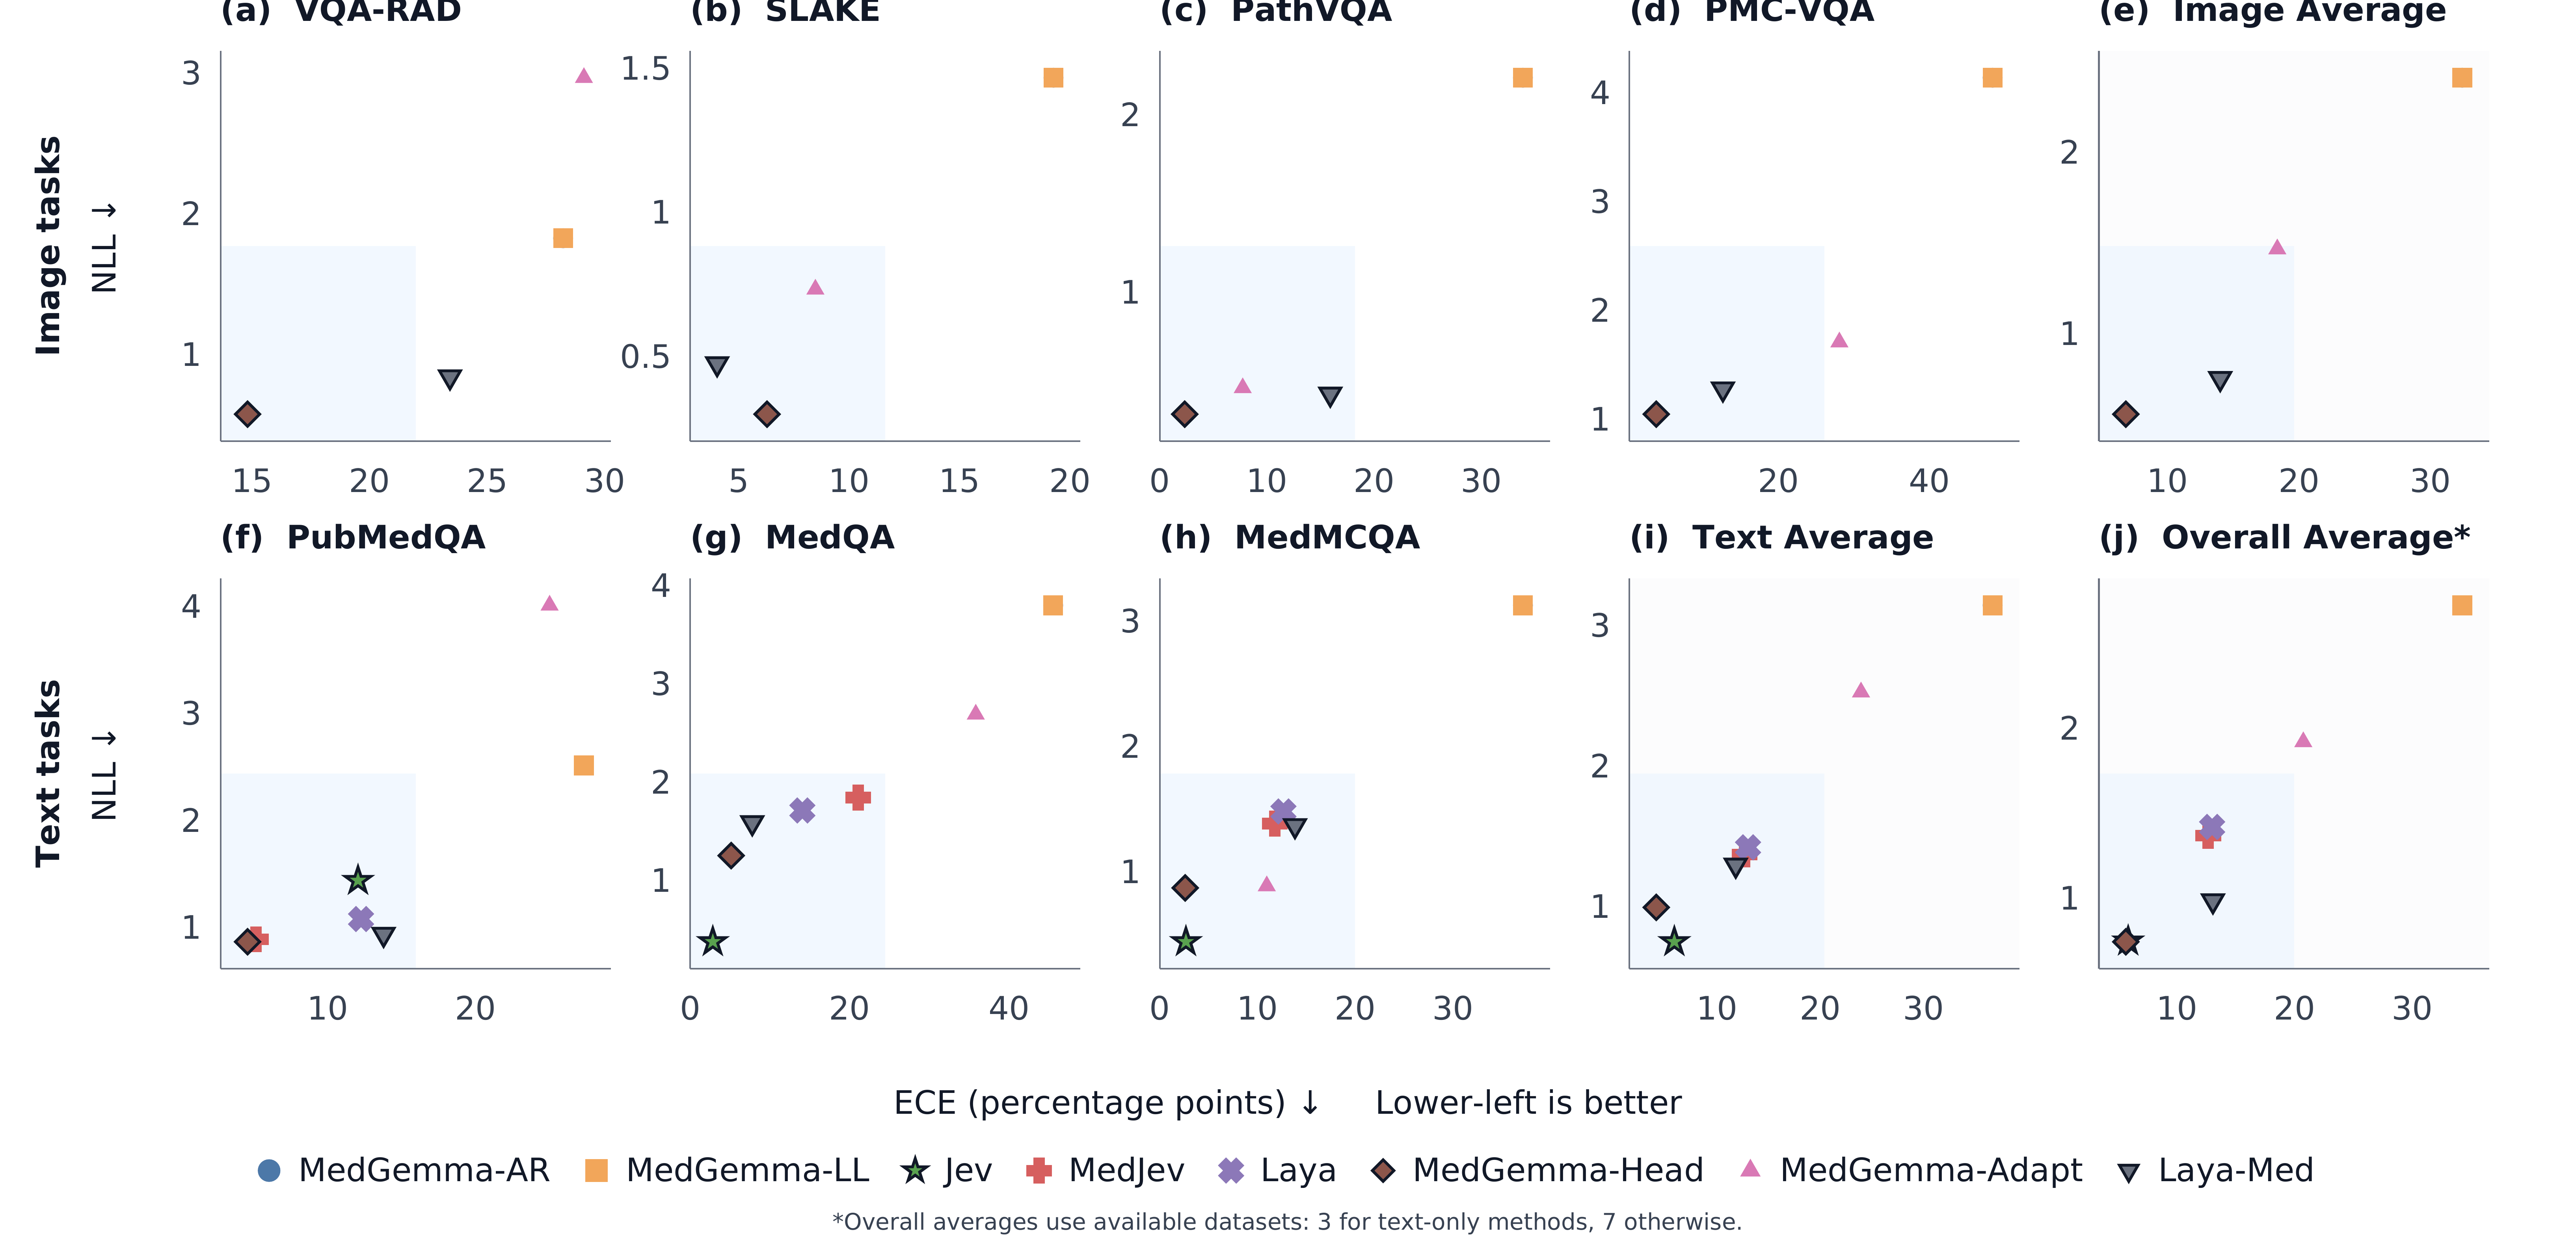

In [44]:
# Install once if needed:
# %pip install reportlab

from pathlib import Path

OUTDIR = Path('figures')
FONT_DIR = None   # e.g. Path('/path/to/DejaVu/fonts'); None = auto-detect
NO_PNG = False

#!/usr/bin/env python3

"""Plot Table 4: probabilistic decision quality, matching the manuscript theme.



Install:  python -m pip install reportlab

Run:      python plot_table4_probabilistic_quality.py --outdir figures

Optional: --font-dir /path/to/DejaVu/fonts --no-png



PDF and SVG are vector outputs. PNG export additionally uses Poppler's pdftoppm

when available; its absence does not prevent PDF/SVG creation.



Data are loaded from results/<model>/results.csv. None means unsupported.

ECE is in percentage points. Both ECE and NLL are lower-is-better.

The blue lower-left quadrant is a directional visual guide, not an acceptance

region or a statistical threshold. Axis ranges differ between panels, as in

the paper's Pareto figure. Averages equally weight supported datasets.

"""

import csv

import importlib.util

import json

import shutil

import subprocess

from pathlib import Path

from reportlab.graphics.shapes import Drawing, Group, String, Rect

from reportlab.graphics.charts.lineplots import LinePlot

from reportlab.graphics.widgets.markers import makeMarker

from reportlab.graphics import renderPDF, renderSVG

from reportlab.lib.colors import HexColor, Color

from reportlab.pdfbase import pdfmetrics

from reportlab.pdfbase.ttfonts import TTFont



METHODS = ['MedGemma-AR', 'MedGemma-LL', 'Jev', 'MedJev', 'Laya', 'MedGemma-Head', 'MedGemma-Adapt', 'Laya-Med']

# Read measured results and fit axes; preserve the existing styling and layout.
import sys
_results_root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "analysis" / "notebook_results.py").is_file()
)
if str(_results_root / "analysis") not in sys.path:
    sys.path.insert(0, str(_results_root / "analysis"))
from notebook_results import load_paper_results, quality_panel_config
_saved_results = load_paper_results()
_quality_groups = {"Text Average": "Text Avg.",
                   "Image Average": "Image Avg.", "Overall Average": "Overall Avg."}
DATA = {
    _quality_groups.get(dataset, dataset): [
        [_saved_results["ece"][dataset][method], _saved_results["nll"][dataset][method]]
        for method in METHODS
    ]
    for dataset in _saved_results["ece"]
}



def locate_fonts(explicit=None):

    candidates = [Path(explicit)] if explicit else []

    candidates += [Path.cwd() / 'fonts',

        Path('/usr/share/fonts/truetype/dejavu'),

        Path('/usr/share/fonts/dejavu'),

        Path('/usr/local/share/fonts'),

        Path('/opt/homebrew/share/fonts/dejavu'),

        Path.home() / '.fonts',

        Path.home() / 'Library/Fonts',

        Path.home() / '.cache/codex-runtimes/codex-primary-runtime/dependencies/native/libreoffice-headless/libreoffice/LibreOfficeDev.app/Contents/Resources/fonts/truetype']

    spec = importlib.util.find_spec('matplotlib')

    if spec and spec.origin:

        candidates.append(Path(spec.origin).parent / 'mpl-data/fonts/ttf')

    for folder in candidates:

        if all((folder / f).exists() for f in ['DejaVuSans.ttf', 'DejaVuSans-Bold.ttf']):

            return folder

    raise SystemExit('DejaVu Sans fonts were not found. Use --font-dir, or install matplotlib (which bundles these fonts).')



def generate(outdir=OUTDIR, font_dir=FONT_DIR, no_png=NO_PNG):

    outdir = Path(outdir)

    outdir.mkdir(parents=True, exist_ok=True)

    font_dir = locate_fonts(font_dir)

    for name, filename in [('DejaVuSans', 'DejaVuSans.ttf'), ('DejaVuSans-Bold', 'DejaVuSans-Bold.ttf')]:

        pdfmetrics.registerFont(TTFont(name, str(font_dir / filename)))

    rows = [dict(dataset=ds, method=m, ece=v[0], nll=v[1])

            for ds, vals in DATA.items() for m, v in zip(METHODS, vals)]

    methods=METHODS

    colors=['#4C78A8','#F2A65A','#59A14F','#D65F5F','#8C78B8','#8C564B','#D979B5','#6B7280']

    kinds=['FilledCircle','FilledSquare','FilledStarFive','Cross','Cross','FilledDiamond','FilledTriangle','FilledTriangle']

    angles=[0,0,0,0,45,0,0,180]

    ink=HexColor('#111827');gray=HexColor('#374151');spine=HexColor('#6B7280')

    # Same physical canvas as the original figure embedded in the manuscript.

    W,H=957.267906,463.868812

    d=Drawing(W,H)

    def txt(x,y,t,size=12,bold=False,align='start',color=ink):

     d.add(String(x,y,t,fontName='DejaVuSans-Bold' if bold else 'DejaVuSans',fontSize=size,fillColor=color,textAnchor=align))

    def marker(j,size=None):

     m=makeMarker(kinds[j]);m.size=size or [7,7,10,8,8,9,7,9][j];m.angle=angles[j];m.fillColor=HexColor(colors[j]);m.strokeColor=ink if j in (2,5,7) else HexColor(colors[j]);m.strokeWidth=1.05 if j in (2,5,7) else (1.6 if j in (3,4) else .4);return m

    cfg = quality_panel_config(DATA, ['VQA-RAD', 'SLAKE', 'PathVQA', 'PMC-VQA', 'Image Avg.', 'PubMedQA', 'MedQA', 'MedMCQA', 'Text Avg.', 'Overall Avg.'])

    placements=[]

    for i,(name,xr,xt,yr,yt) in enumerate(cfg):

     col=i%5;row=i//5;x=82+col*174.5;y=300 if row==0 else 104;w=145;h=145

     if 'Avg.' in name:d.add(Rect(x,y,w,h,fillColor=HexColor('#FCFCFD'),strokeColor=None))

     # Match the Pareto plot's pale-blue emphasis, now in the lower-left.

     d.add(Rect(x,y,w/2,h/2,fillColor=Color(238/255,246/255,1,alpha=.75),strokeColor=None))

     plot=LinePlot();plot.x=x;plot.y=y;plot.width=w;plot.height=h

     inds=[j for j,m in enumerate(methods) if next(r for r in rows if r['dataset']==name and r['method']==m)['ece'] is not None]

     data=[]

     for j in inds:

      r=next(r for r in rows if r['dataset']==name and r['method']==methods[j]);data.append([(r['ece'],r['nll'])]);placements.append({'dataset':name,'method':methods[j],'ece':r['ece'],'nll':r['nll'],'x':x+(r['ece']-xr[0])/(xr[1]-xr[0])*w,'y':y+(r['nll']-yr[0])/(yr[1]-yr[0])*h})

     plot.data=data

     for k,j in enumerate(inds):

      plot.lines[k].strokeColor=None;plot.lines[k].strokeWidth=0;plot.lines[k].symbol=marker(j)

     for axis,lim,ticks in [(plot.xValueAxis,xr,xt),(plot.yValueAxis,yr,yt)]:

      axis.valueMin,axis.valueMax=lim;axis.valueSteps=ticks;axis.forceZero=False;axis.visibleGrid=False;axis.strokeColor=spine;axis.strokeWidth=.6;axis.visibleTicks=False;axis.labels.fontName='DejaVuSans';axis.labels.fontSize=12;axis.labels.fillColor=gray;axis.labelTextFormat=lambda v:f'{v:g}'

     plot.xValueAxis.labels.dy=-7;plot.xValueAxis.labels.boxAnchor='n';plot.yValueAxis.labels.dx=-7;plot.yValueAxis.labels.boxAnchor='e'

     # Keep the x axis at the bottom of every panel.

     plot.xValueAxis.joinAxisMode='bottom';plot.yValueAxis.joinAxisMode='left'

     d.add(plot)

     title=name.replace('Avg.','Average')+('*' if name=='Overall Avg.' else '')

     txt(x,y+h+11,f'({chr(97+i)})  {title}',12,True)

    # Figure labels and footer match the manuscript's plotting typography.

    for label,cy in [('Image tasks',372.5),('Text tasks',176.5)]:

     g=Group();g.add(String(0,0,label,fontName='DejaVuSans-Bold',fontSize=12,fillColor=ink,textAnchor='middle'));g.translate(22,cy);g.rotate(90);d.add(g)

     g=Group();g.add(String(0,0,'NLL ↓',fontName='DejaVuSans',fontSize=12,fillColor=ink,textAnchor='middle'));g.translate(43,cy);g.rotate(90);d.add(g)

    txt(W/2,50,'ECE (percentage points) ↓     Lower-left is better',12,align='middle')

    widths=[16+pdfmetrics.stringWidth(m,'DejaVuSans',12)+12 for m in methods];xx=(W-sum(widths)+12)/2

    for j,m in enumerate(methods):

     q=marker(j,8 if j!=2 else 9);q.x=xx+4;q.y=29;d.add(q);txt(xx+15,25,m,12);xx+=widths[j]

    txt(W/2,7,'*Overall averages use available datasets: 3 for text-only methods, 7 otherwise.',8.5,align='middle',color=gray)

    assert len(placements)==65



    stem = outdir / 'table4_probabilistic_quality'

    # Uniform physical scaling: 4.5 x 4.5 inches per data panel.
    panel_scale = (4.5 * 72) / 145
    d.scale(panel_scale, panel_scale)
    d.width *= panel_scale
    d.height *= panel_scale
    renderPDF.drawToFile(d, str(stem.with_suffix('.pdf')), title='Probabilistic decision quality')

    renderSVG.drawToFile(d, str(stem.with_suffix('.svg')))

    with (outdir / 'table4_probabilistic_quality_data.csv').open('w', newline='') as f:

        writer = csv.DictWriter(f, fieldnames=['dataset','method','ece','nll'])

        writer.writeheader()

        writer.writerows(rows)

    if not no_png:

        poppler = shutil.which('pdftoppm')

        bundled = Path.home() / '.cache/codex-runtimes/codex-primary-runtime/dependencies/bin/override/pdftoppm'

        if not poppler and bundled.exists():

            poppler = str(bundled)

        if poppler:

            subprocess.run([poppler, '-r', '220', '-png', '-singlefile', str(stem.with_suffix('.pdf')), str(stem)], check=True)

        else:

            print('PNG skipped: install Poppler to enable pdftoppm.')

    assert len(placements) == 65

    print(f'Saved 10 panels, with all 65 available ECE/NLL pairs, to {outdir}')



generate()

# Display the generated plot inline
from IPython.display import Image, display
png = OUTDIR / 'table4_probabilistic_quality.png'
if png.exists():
    display(Image(filename=str(png)))
else:
    print('PNG was not generated (Poppler/pdftoppm may be unavailable). PDF and SVG are still saved in', OUTDIR)

## Medical SysOne: Empirical Results for the Paper

The cells below read the saved 50-example-per-dataset CSV exports and generate paper-styled figures and a compact paired-effect table. Each figure is saved as both vector PDF and high-resolution PNG under `analysis/figures/paper_results/`.

In [45]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

# Resolve project root independently of whether Jupyter starts in repo/ or analysis/.
_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _candidates if (p / "experiment_results/main_results.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Could not locate experiment_results/main_results.csv from the notebook cwd")
RESULTS = ROOT / "experiment_results"
PAPER_FIGURES = ROOT / "analysis/figures/paper_results"
PAPER_FIGURES.mkdir(parents=True, exist_ok=True)

INK = "#223F52"
MUTED = "#687985"
PREFERRED = "#EEF6FF"
PALETTE = {
    "MedGemma-AR": "#4C78A8",
    "MedGemma-LL": "#F2A65A",
    "MedGemma-Constrained": "#2A9D8F",
    "MedGemma-Head": "#8C564B",
    "MedGemma-Adapt": "#D979B5",
    "Laya-Med": "#6B7280",
}
DATASET_NAMES = {
    "pubmedqa": "PubMedQA", "med_qa": "MedQA", "medmcqa": "MedMCQA",
    "vqarad": "VQA-RAD", "slake": "SLAKE", "path_vqa": "PathVQA",
    "pmc_vqa": "PMC-VQA",
}
DATASET_ORDER = ["pubmedqa", "med_qa", "medmcqa", "vqarad", "slake", "path_vqa", "pmc_vqa"]
IMAGE_SET = {"vqarad", "slake", "path_vqa", "pmc_vqa"}
TEXT_SET = set(DATASET_ORDER) - IMAGE_SET

# Shared typography and exact 4.5-inch square data panels.
import sys
if str(ROOT / "analysis") not in sys.path:
    sys.path.insert(0, str(ROOT / "analysis"))
import importlib
import paper_plot_style
importlib.reload(paper_plot_style)
from paper_plot_style import (
    apply_style, panel_grid, panel_title, prefer, legend_panel,
    figure_legend, add_colorbar, save_figure, MODEL_MARKERS,
    FONT_SIZE, ANNOTATION_SIZE, INK, MUTED, PREFERRED,
    model_marker, model_handle, MODEL_COLORS, MODEL_DASHES, enlarge_coverage_axes, risk_limits,
)
apply_style()

def save(fig, stem):
    save_figure(fig, PAPER_FIGURES, stem)

def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]

def confidence_and_correct(row):
    if "probabilities" in row:
        p = np.asarray(row["probabilities"], dtype=float)
    else:
        z = np.asarray(row["logits"], dtype=float) / float(row.get("temperature", 1.0))
        p = np.exp(z - z.max())
        p /= p.sum()
    prediction = int(row.get("prediction", p.argmax()))
    return float(row.get("confidence", p.max())), prediction == int(row["label"])

main_results = pd.read_csv(RESULTS / "main_results.csv")
main_results["model"] = main_results["model"].replace({"MedGemma-LoRA": "MedGemma-Adapt"})
paired_files = {
    "LL vs Head": RESULTS / "ll_vs_head_paired.csv",
    "Head vs Adapt": RESULTS / "head_vs_lora_paired.csv",
}
paired = {name: pd.read_csv(path) for name, path in paired_files.items()}
visual_laya = pd.read_csv(RESULTS / "visual_dependence/visual_dependence.csv")
visual_lora = pd.read_csv(RESULTS / "visual_dependence_medgemma_lora/visual_dependence.csv")
posthoc = pd.read_csv(RESULTS / "posthoc/posthoc_policy_results.csv")
risk_coverage = pd.read_csv(RESULTS / "posthoc/risk_coverage_points.csv")
scaling = pd.read_csv(RESULTS / "candidate_scaling/candidate_scaling.csv")

print(f"Loaded {len(main_results)} model-dataset rows; output directory: {PAPER_FIGURES}")

Loaded 42 model-dataset rows; output directory: /home/razaimam/Documents/Projects/Jevify/analysis/figures/paper_results


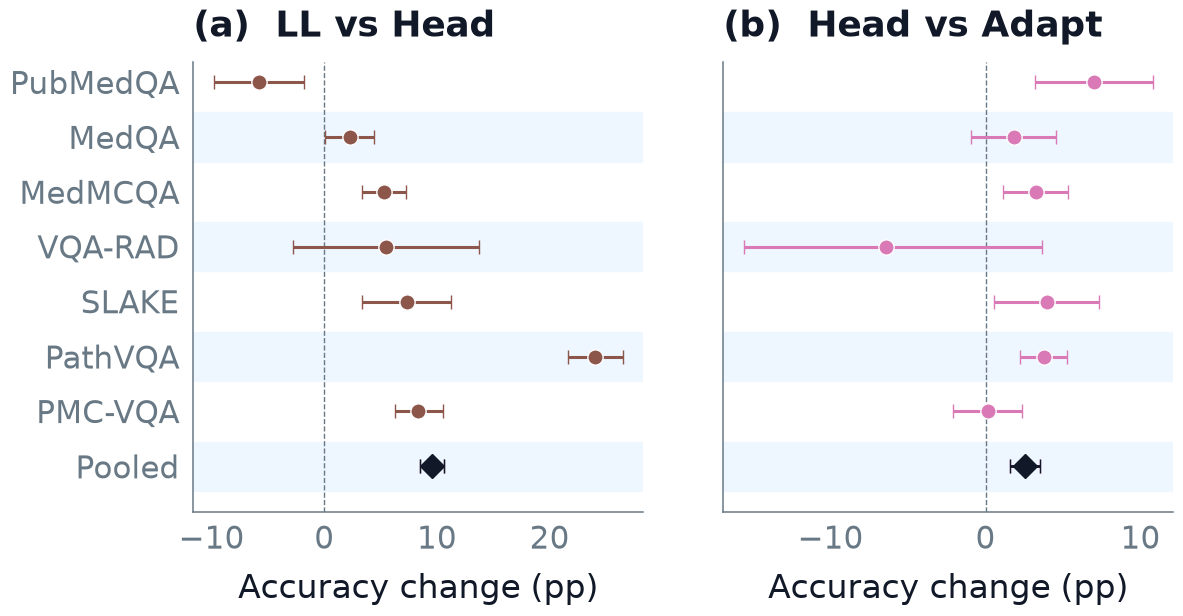

In [46]:
# Paired accuracy effect by dataset (candidate minus reference, paired bootstrap 95% CI);
# the pooled estimate is the bottom row.
comparison_order = ["LL vs Head", "Head vs Adapt"]
comparison_colors = {"LL vs Head": PALETTE["MedGemma-Head"], "Head vs Adapt": PALETTE["MedGemma-Adapt"]}
row_order = (DATASET_ORDER + ["__pooled__"])[::-1]
fig, axes = panel_grid(1, 2, sharey=True)
for ax, comparison in zip(axes, comparison_order):
    frame = paired[comparison].copy()
    frame["dataset"] = pd.Categorical(frame.dataset, categories=row_order, ordered=True)
    frame = frame.sort_values("dataset")
    y = np.arange(len(frame))
    delta = frame.accuracy_delta.to_numpy() * 100
    low = (frame.accuracy_delta - frame.accuracy_ci_low).to_numpy() * 100
    high = (frame.accuracy_ci_high - frame.accuracy_delta).to_numpy() * 100
    color = comparison_colors[comparison]
    for stripe in range(0, len(frame), 2):
        ax.axhspan(stripe - .45, stripe + .45, color=PREFERRED, zorder=0)
    ax.errorbar(delta, y, xerr=[low, high], fmt="o", color=color, ecolor=color,
                capsize=5, markersize=11, linewidth=2.2, markeredgecolor="white")
    pooled = np.where(frame.dataset.astype(str).to_numpy() == "__pooled__")[0]
    ax.errorbar(delta[pooled], y[pooled], xerr=[low[pooled], high[pooled]], fmt="D", color=INK,
                ecolor=INK, capsize=5, markersize=12, linewidth=2)
    ax.axvline(0, color=MUTED, linewidth=1, linestyle="--", zorder=1)
    ax.set_yticks(y, [DATASET_NAMES.get(d, "Pooled") for d in frame.dataset.astype(str)])
    panel_title(ax, comparison_order.index(comparison), comparison)
    ax.set_xlabel("Accuracy change (pp)")
save(fig, "paired_accuracy_effects")
plt.show()


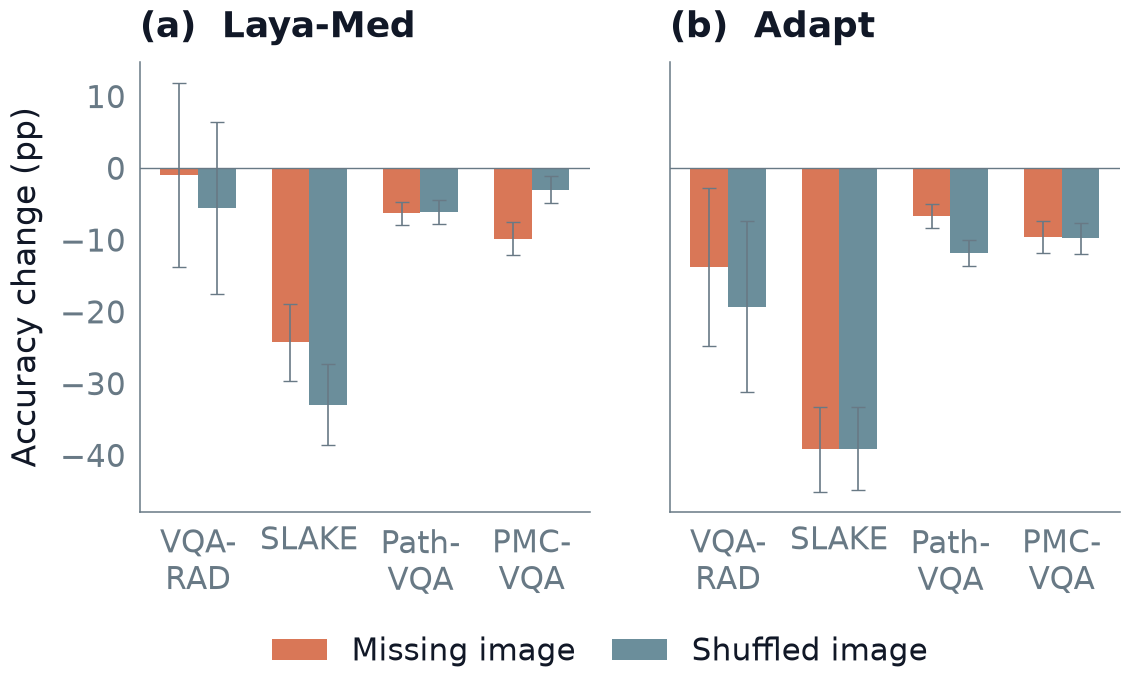

In [47]:
# Paired image-dependence ablation: accuracy change from the correct image.
IMAGE_DATASETS = ["vqarad", "slake", "path_vqa", "pmc_vqa"]
visual_frames = {
    "Laya-Med": visual_laya[visual_laya.dataset.isin(IMAGE_DATASETS)].copy(),
    "Adapt": visual_lora[visual_lora.dataset.isin(IMAGE_DATASETS)].copy(),
}
conditions = ["missing_image", "shuffled_image"]
condition_colors = {"missing_image": "#D97757", "shuffled_image": "#6B8E9B"}
fig, axes = panel_grid(1, 2, legend=True, sharey=True)
x = np.arange(len(IMAGE_DATASETS))
width = .34
for ax, (model, frame) in zip(axes, visual_frames.items()):
    for offset, condition in enumerate(conditions):
        subset = frame[frame.condition == condition].set_index("dataset").reindex(IMAGE_DATASETS)
        delta = subset.delta.to_numpy() * 100
        lower = (subset.delta - subset.ci_low).to_numpy() * 100
        upper = (subset.ci_high - subset.delta).to_numpy() * 100
        ax.bar(x + (offset - .5) * width, delta, width, color=condition_colors[condition],
               label=condition.replace("_", " ").capitalize(), edgecolor="none",
               yerr=np.vstack([lower, upper]), capsize=5, error_kw={"ecolor": MUTED, "elinewidth": 1.2})
    ax.axhline(0, color=MUTED, linewidth=1)
    panel_title(ax, list(visual_frames).index(model), model)
    ax.set_xticks(x, ["VQA-\nRAD", "SLAKE", "Path-\nVQA", "PMC-\nVQA"])
axes[0].set_ylabel("Accuracy change (pp)")
handles, labels = axes[0].get_legend_handles_labels()
figure_legend(fig, handles, labels, ncols=2)
save(fig, "visual_dependence_ablation")
plt.show()


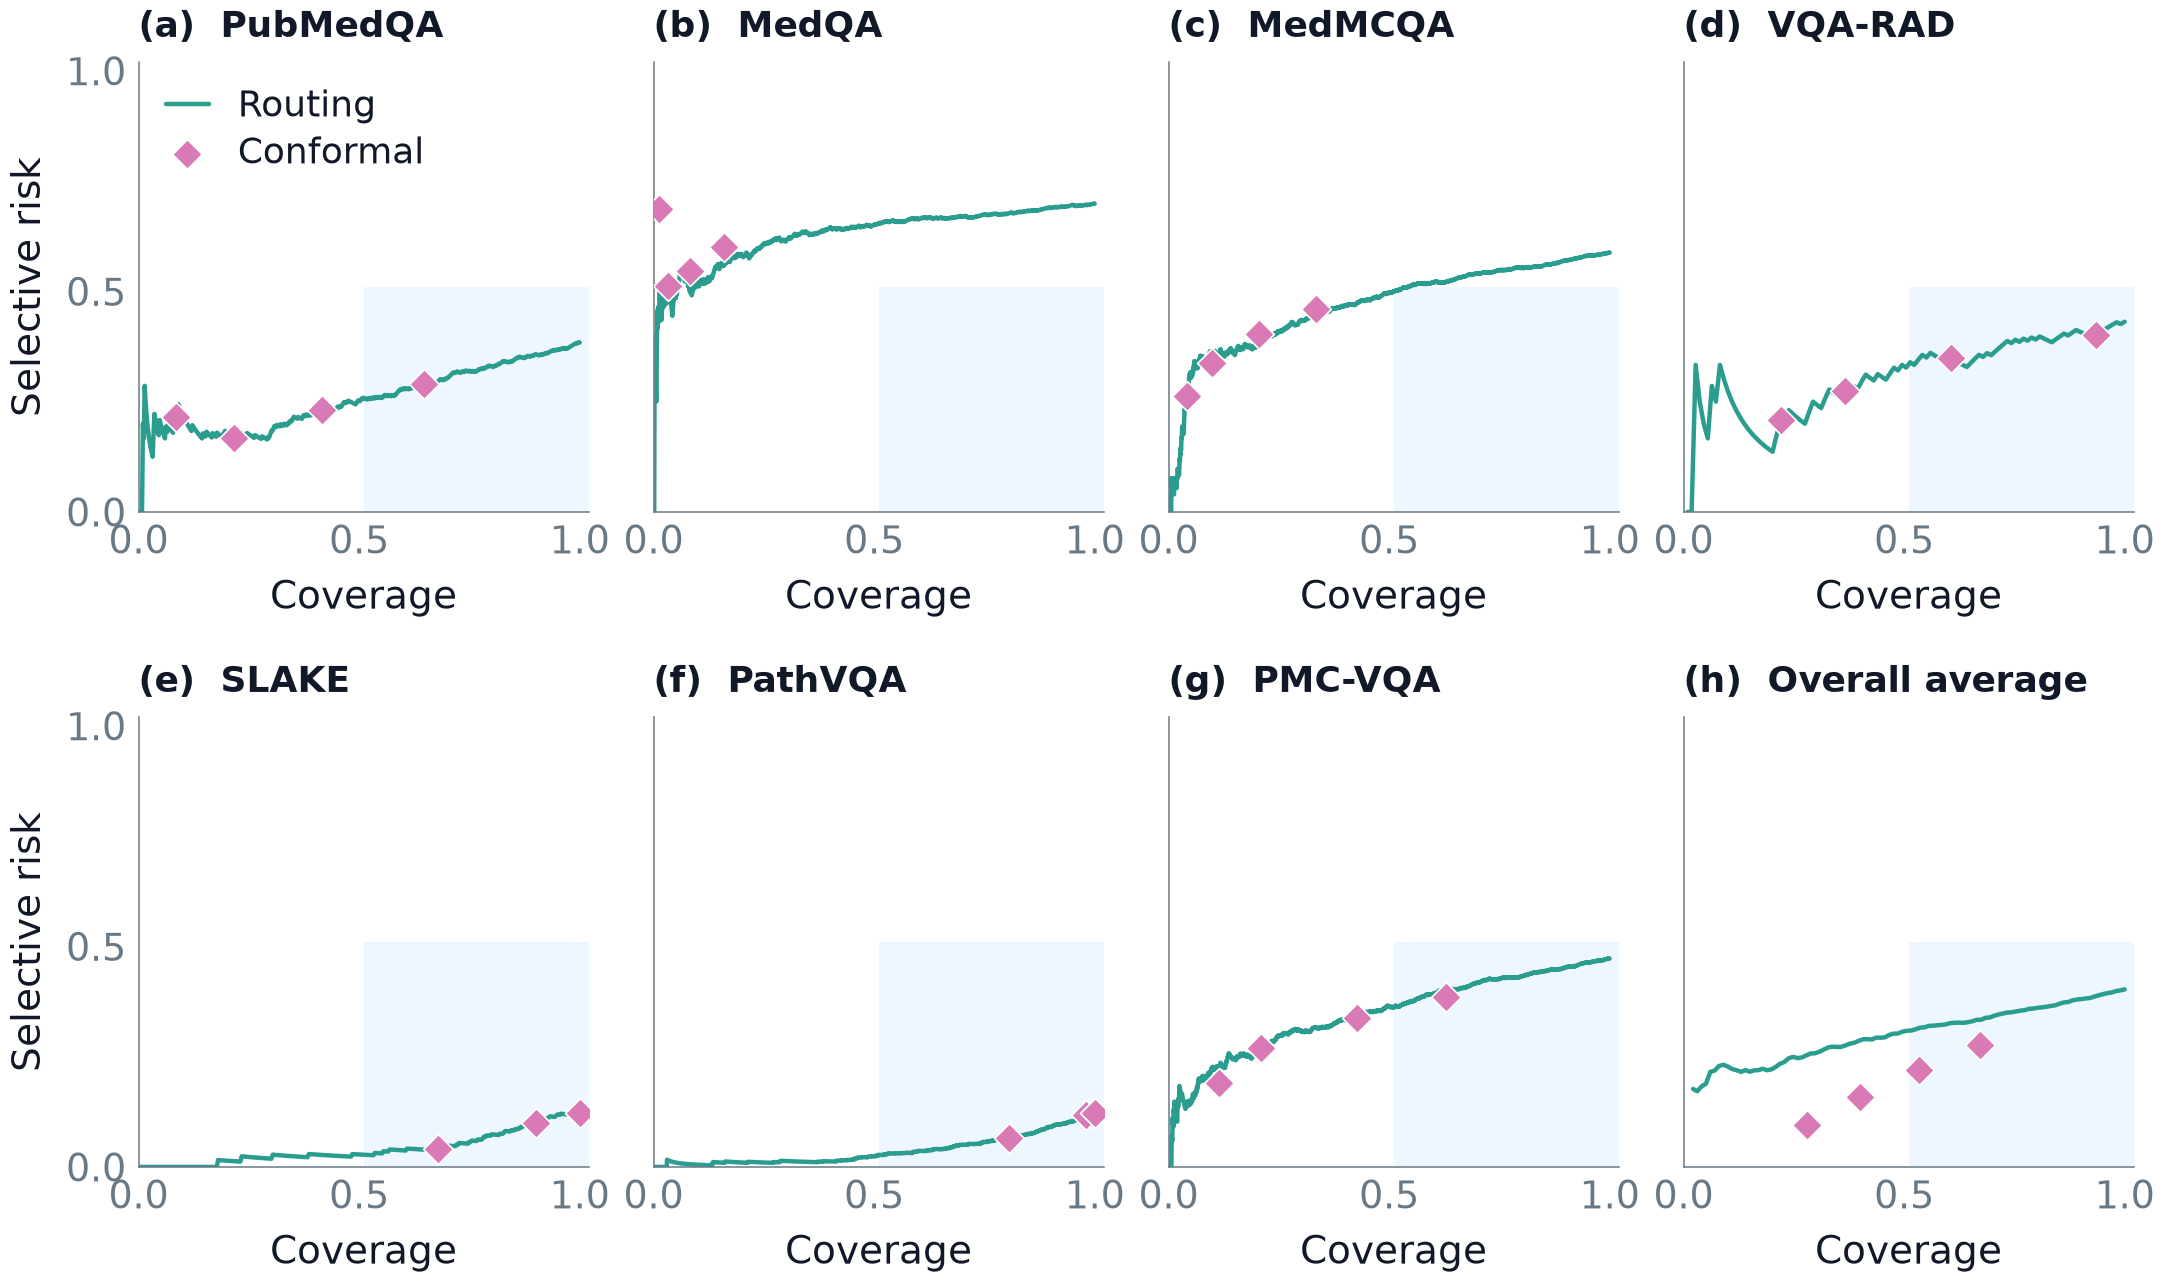

In [48]:
# Per-dataset policies plus a dataset-balanced overall average.
laya_rows = read_jsonl(RESULTS / "laya/correct-test.predictions.jsonl")
laya_by_dataset = {}
for row in laya_rows:
    laya_by_dataset.setdefault(row.get("dataset", row.get("task")), []).append(confidence_and_correct(row))
ROUTING_COLOR, CONFORMAL_COLOR = PALETTE["MedGemma-Constrained"], PALETTE["MedGemma-Adapt"]
conformal_points = posthoc[posthoc.policy == "conformal"].copy()
conformal_points["parameter"] = conformal_points.parameter.astype(float)

# Equal dataset weights: coverage = mean accepted fraction; risk = weighted
# error fraction / weighted accepted fraction. Zero-acceptance tasks stay in
# the denominator rather than disappearing from an unweighted risk average.
overall_policy_rows = []
for target in np.linspace(.02, 1, 100):
    accepted_fractions, error_fractions = [], []
    for dataset in DATASET_ORDER:
        ordered = sorted(laya_by_dataset[dataset], key=lambda item: -item[0])
        retained = min(len(ordered), max(1, int(np.ceil(target * len(ordered)))))
        accepted_fractions.append(retained / len(ordered))
        error_fractions.append(sum(not correct for _, correct in ordered[:retained]) / len(ordered))
    coverage = float(np.mean(accepted_fractions))
    overall_policy_rows.append(dict(policy="Routing", parameter=target, coverage=coverage,
                                    risk=float(np.mean(error_fractions) / coverage)))
for alpha, frame in conformal_points.groupby("parameter"):
    assert len(frame) == len(DATASET_ORDER) and set(frame.dataset) == set(DATASET_ORDER)
    coverage = float(frame.coverage.mean())
    error_fraction = ((1 - frame.accepted_accuracy).fillna(0) * frame.coverage).mean()
    overall_policy_rows.append(dict(policy="Conformal", parameter=alpha, coverage=coverage,
                                    risk=float(error_fraction / coverage) if coverage else np.nan))
overall_policy = pd.DataFrame(overall_policy_rows)
overall_policy.to_csv(PAPER_FIGURES / "overall_posthoc_risk_coverage.csv", index=False)

fig, axes = panel_grid(2, 4, sharex=True, sharey=True, xgap=.65, ygap=2.05)
for index, dataset in enumerate(DATASET_ORDER + ["__overall__"]):
    ax = axes.flat[index]
    prefer(ax, "right", "bottom")
    if dataset == "__overall__":
        curve = overall_policy[overall_policy.policy == "Routing"].sort_values("coverage")
        points = overall_policy[overall_policy.policy == "Conformal"].dropna(subset=["risk"])
        coverage, risk = curve.coverage, curve.risk
        point_coverage, point_risk = points.coverage, points.risk
        title = "Overall average"
    else:
        ordered = sorted(laya_by_dataset[dataset], key=lambda item: -item[0])
        kept = np.arange(1, len(ordered) + 1)
        coverage = kept / len(ordered)
        risk = np.cumsum([not correct for _, correct in ordered]) / kept
        points = conformal_points[(conformal_points.dataset == dataset) & conformal_points.accepted_accuracy.notna()]
        point_coverage, point_risk = points.coverage, 1 - points.accepted_accuracy
        title = DATASET_NAMES[dataset]
    ax.plot(coverage, risk, color=ROUTING_COLOR, linewidth=3.2, solid_capstyle="round", label="Routing")
    ax.scatter(point_coverage, point_risk, s=230, marker="D", color=CONFORMAL_COLOR,
               edgecolor="white", linewidth=1.2, zorder=4, label="Conformal")
    panel_title(ax, index, title)
    ax.set_xlabel("Coverage")
    if index % 4 == 0:
        ax.set_ylabel("Selective risk")
    ax.set(xlim=(0, 1.02), ylim=(0, 1.02), xticks=[0, .5, 1], yticks=[0, .5, 1])
axes.flat[0].legend(loc="upper left", fontsize=26, handlelength=1.2,
                    labelspacing=.3, borderaxespad=.35)
enlarge_coverage_axes(axes)
save(fig, "posthoc_risk_coverage")
plt.show()


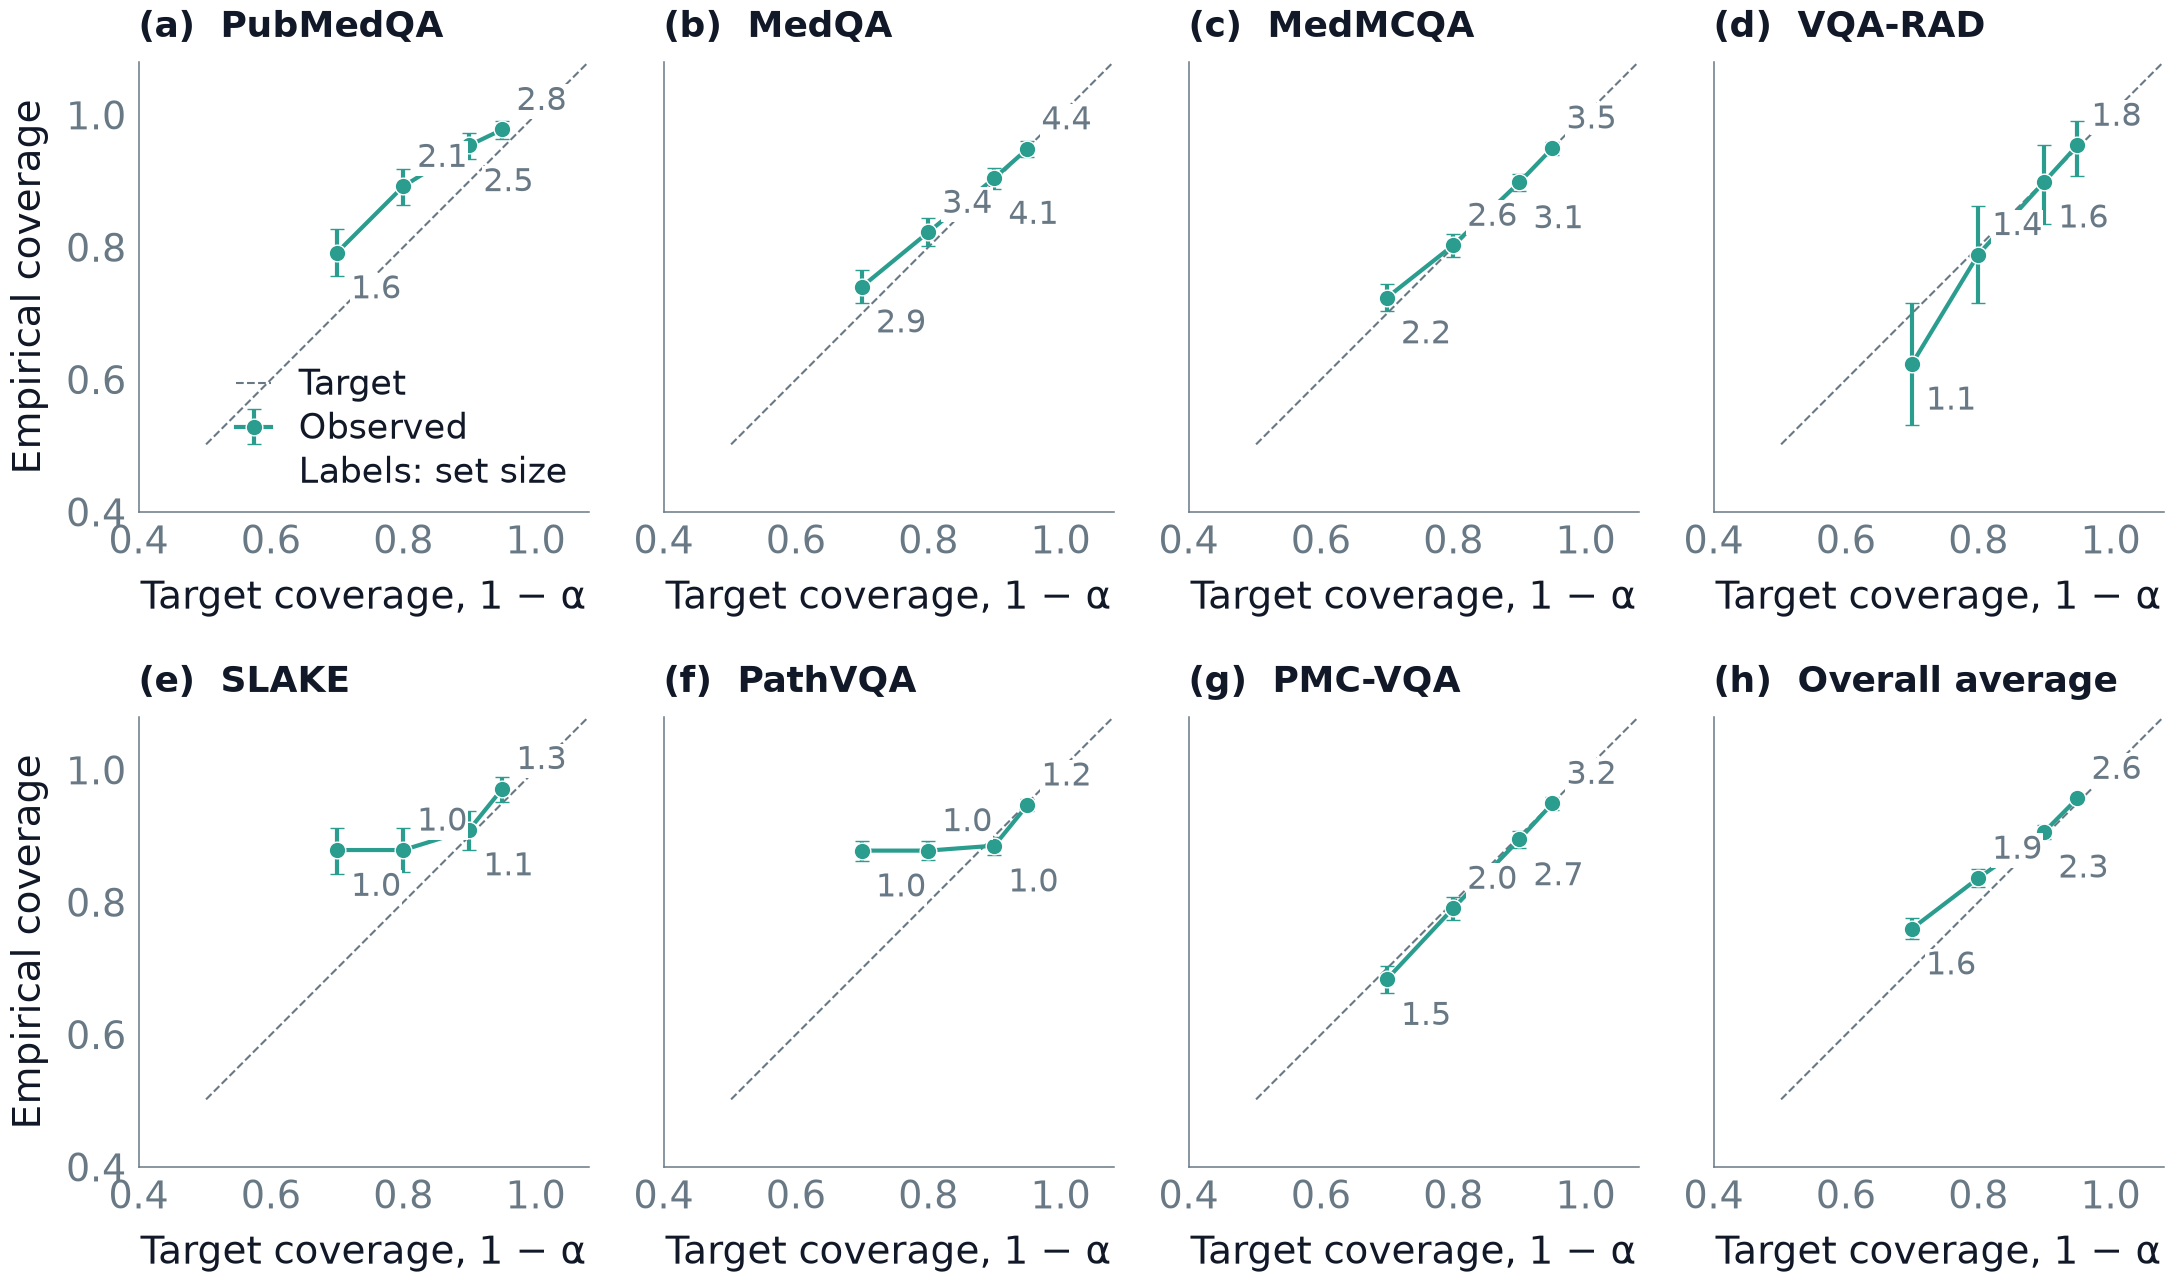

In [49]:
# Empirical coverage and mean set size; the last panel equally weights datasets.
conformal = posthoc[posthoc.policy == "conformal"].copy()
conformal["parameter"] = conformal.parameter.astype(float)
conformal["target_coverage"] = 1 - conformal.parameter
rng = np.random.default_rng(42)
overall_coverage_rows = []
for alpha, frame in conformal.groupby("parameter"):
    assert len(frame) == len(DATASET_ORDER) and set(frame.dataset) == set(DATASET_ORDER)
    sizes = frame.n.to_numpy(dtype=int)
    rates = frame.empirical_label_coverage.to_numpy()
    assert np.allclose(rates * sizes, np.round(rates * sizes))
    # Stratified bootstrap of binary coverage, equivalent to resampling each
    # dataset's covered/not-covered observations. Do not average CI endpoints.
    replicates = (rng.binomial(sizes, rates, size=(5000, len(frame))) / sizes).mean(axis=1)
    low, high = np.quantile(replicates, [.025, .975])
    overall_coverage_rows.append(dict(dataset="__overall__", parameter=alpha, target_coverage=1-alpha,
        empirical_label_coverage=float(rates.mean()), empirical_label_coverage_ci_low=float(low),
        empirical_label_coverage_ci_high=float(high), mean_set_size=float(frame.mean_set_size.mean())))
overall_conformal = pd.DataFrame(overall_coverage_rows)
overall_conformal.to_csv(PAPER_FIGURES / "overall_conformal_coverage.csv", index=False)
coverage_panels = pd.concat([conformal, overall_conformal], ignore_index=True)
lower = max(0, min(.6, coverage_panels.empirical_label_coverage_ci_low.min()) - .03)
fig, axes = panel_grid(2, 4, sharex=True, sharey=True, xgap=.75, ygap=2.05)
for index, dataset in enumerate(DATASET_ORDER + ["__overall__"]):
    ax = axes.flat[index]
    frame = coverage_panels[coverage_panels.dataset == dataset].sort_values("target_coverage")
    ax.plot([lower, 1.08], [lower, 1.08], color=MUTED, linestyle="--", linewidth=1.5, label="Target")
    ax.errorbar(frame.target_coverage, frame.empirical_label_coverage,
                yerr=[frame.empirical_label_coverage-frame.empirical_label_coverage_ci_low,
                      frame.empirical_label_coverage_ci_high-frame.empirical_label_coverage],
                fmt="o-", color=PALETTE["MedGemma-Constrained"], capsize=5, linewidth=3,
                markersize=12, markeredgecolor="white", label="Observed")
    for position, row in enumerate(frame.itertuples()):
        ax.annotate(f"{row.mean_set_size:.1f}", (row.target_coverage, row.empirical_label_coverage),
                    xytext=(10, -33 if position % 2 == 0 else 14), textcoords="offset points",
                    ha="left", fontsize=23, color=MUTED, zorder=6,
                    bbox={"facecolor":"white", "edgecolor":"none", "pad":1})
    panel_title(ax, index, "Overall average" if dataset == "__overall__" else DATASET_NAMES[dataset])
    ax.set_xlabel("Target coverage, 1 − α")
    if index % 4 == 0:
        ax.set_ylabel("Empirical coverage")
    ax.set(xlim=(lower, 1.08), ylim=(lower, 1.08), xticks=[.4,.6,.8,1.0], yticks=[.4,.6,.8,1.0])
handles, labels = axes.flat[0].get_legend_handles_labels()
handles.append(Line2D([], [], linestyle="none")); labels.append("Labels: set size")
axes.flat[0].legend(handles, labels, loc="lower right", fontsize=25,
                    handlelength=1.0, labelspacing=.25, borderaxespad=.2)
enlarge_coverage_axes(axes)
save(fig, "conformal_coverage")
plt.show()


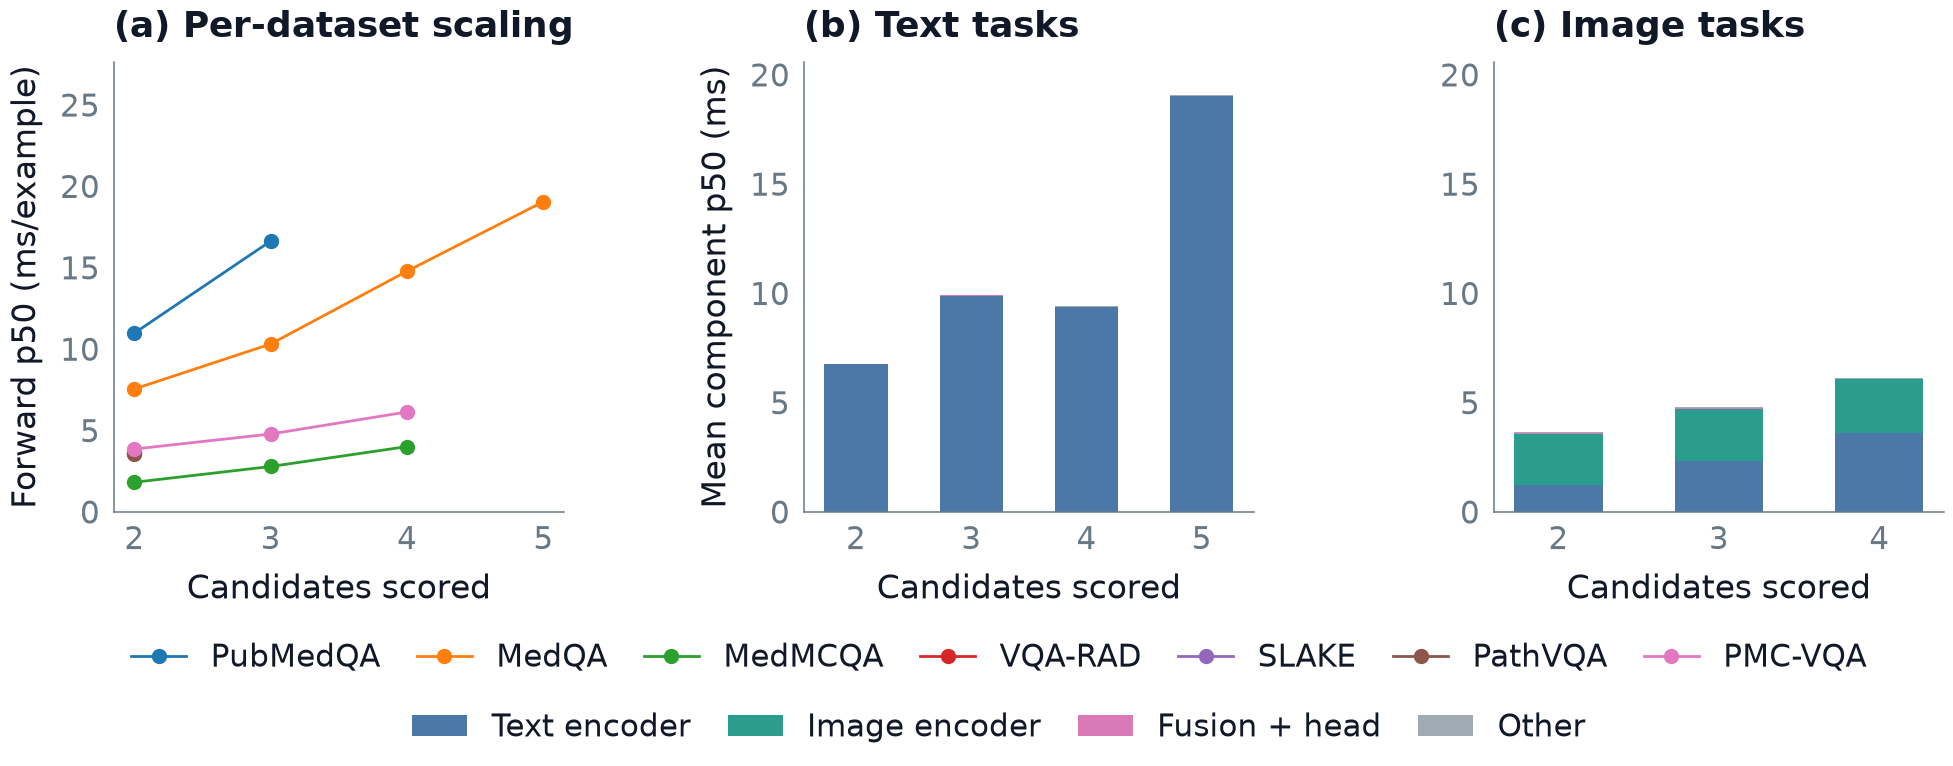

In [50]:
# Laya-Med inference cost as candidates grow, plus forward-pass composition by task type.
scaling["task_group"] = np.where(scaling.dataset.isin(IMAGE_SET), "Image tasks", "Text tasks")
fig, axes = panel_grid(1, 3, legend=True, xgap=2.4)
for dataset in DATASET_ORDER:
    frame = scaling[scaling.dataset == dataset].sort_values("candidate_count")
    if frame.empty:
        continue
    axes[0].plot(frame.candidate_count, frame.forward_p50_ms_per_example,
                 marker="o", markersize=10, linewidth=2, label=DATASET_NAMES[dataset])
axes[0].set_xlabel("Candidates scored")
axes[0].set_xticks([2, 3, 4, 5])
axes[0].set_ylabel("Forward p50 (ms/example)")
axes[0].set_ylim(0, scaling.forward_p50_ms_per_example.max() * 1.45)
axes[0].set_title("(a) Per-dataset scaling", loc="left", pad=18)
dataset_handles, dataset_labels = axes[0].get_legend_handles_labels()
figure_legend(fig, dataset_handles, dataset_labels, ncols=7, row=1)
component_cols = ["text_encoder_p50_ms_per_example", "image_encoder_p50_ms_per_example",
                  "fusion_head_p50_ms_per_example", "other_forward_p50_ms_per_example"]
component_labels = ["Text encoder", "Image encoder", "Fusion + head", "Other"]
component_colors = ["#4C78A8", "#2A9D8F", "#D979B5", "#A0AAB2"]
summary_scaling = scaling.groupby(["task_group", "candidate_count"], as_index=False)[component_cols].mean()
top = summary_scaling[component_cols].sum(axis=1).max() * 1.08
for ax, task_group, tag in [(axes[1], "Text tasks", "(b)"), (axes[2], "Image tasks", "(c)")]:
    frame = summary_scaling[summary_scaling.task_group == task_group].sort_values("candidate_count")
    bottom = np.zeros(len(frame))
    for column, label, color in zip(component_cols, component_labels, component_colors):
        values = frame[column].to_numpy()
        ax.bar(frame.candidate_count, values, width=.55, bottom=bottom, color=color,
               edgecolor="none", label=label)
        bottom += values
    ax.set_xticks(frame.candidate_count.astype(int))
    ax.set_xlabel("Candidates scored")
    ax.set_ylim(0, top)
    ax.set_title(f"{tag} {task_group}", loc="left", pad=18)
axes[1].set_ylabel("Mean component p50 (ms)")
handles, labels = axes[1].get_legend_handles_labels()
figure_legend(fig, handles, labels, ncols=4)
save(fig, "candidate_count_scaling")
plt.show()


In [51]:
# Table: paired effects for the controlled/closest contrasts, exportable to LaTeX.
paired_table = pd.concat([
    paired[name].loc[paired[name].dataset != "__pooled__"].assign(comparison=name)
    for name in comparison_order
], ignore_index=True)
paired_table["dataset"] = paired_table.dataset.map(DATASET_NAMES).fillna(paired_table.dataset)
paired_table["dataset_order"] = paired_table.dataset.map({DATASET_NAMES[d]: i for i, d in enumerate(DATASET_ORDER)})
paired_table["comparison_order"] = paired_table.comparison.map({name: i for i, name in enumerate(comparison_order)})
paired_table = paired_table.sort_values(["comparison_order", "dataset_order"])
paired_table["Accuracy Δ (pp), 95% CI"] = paired_table.apply(
    lambda r: f"{100*r.accuracy_delta:+.1f} [{100*r.accuracy_ci_low:+.1f}, {100*r.accuracy_ci_high:+.1f}]", axis=1)
paired_table["NLL Δ, 95% CI"] = paired_table.apply(
    lambda r: f"{r.nll_delta:+.2f} [{r.nll_ci_low:+.2f}, {r.nll_ci_high:+.2f}]", axis=1)
paired_table["Brier Δ"] = paired_table.brier_delta.map(lambda x: "--" if pd.isna(x) else f"{x:+.3f}")
paired_export = paired_table[["comparison", "dataset", "n", "Accuracy Δ (pp), 95% CI", "NLL Δ, 95% CI", "Brier Δ"]]
paired_export.to_csv(PAPER_FIGURES / "paired_effects_table.csv", index=False)
latex = paired_export.to_latex(index=False, escape=True, column_format="llrlll",
    caption="Paired model differences on matched examples. Deltas are candidate minus reference; accuracy is in percentage points. Confidence intervals are paired bootstrap 95\\% intervals. Negative NLL/Brier differences favor the candidate.",
    label="tab:paired_effects", longtable=True)
(PAPER_FIGURES / "paired_effects_table.tex").write_text(latex)
display(paired_export.head(12))
print(f"Saved CSV and LaTeX table to {PAPER_FIGURES}")


,comparison,dataset,n,"Accuracy Δ (pp), 95% CI","NLL Δ, 95% CI",Brier Δ
4,LL vs Head,PubMedQA,500,"-5.8 [-9.8, -1.8]","-1.65 [-2.01, -1.30]",-0.054
0,LL vs Head,MedQA,1268,"+2.3 [+0.1, +4.4]","-2.55 [-2.75, -2.34]",-0.322
1,LL vs Head,MedMCQA,2000,"+5.3 [+3.3, +7.2]","-2.25 [-2.41, -2.09]",-0.301
6,LL vs Head,VQA-RAD,109,"+5.5 [-2.8, +13.8]","-1.26 [-1.84, -0.73]",-0.184
5,LL vs Head,SLAKE,355,"+7.3 [+3.4, +11.3]","-1.17 [-1.47, -0.88]",-0.204
2,LL vs Head,PathVQA,2000,"+24.1 [+21.6, +26.5]","-1.90 [-2.04, -1.77]",-0.507
3,LL vs Head,PMC-VQA,1980,"+8.3 [+6.3, +10.6]","-3.09 [-3.27, -2.90]",-0.419
11,Head vs Adapt,PubMedQA,500,"+7.0 [+3.2, +10.8]","+0.18 [+0.05, +0.32]",-0.032
7,Head vs Adapt,MedQA,1268,"+1.8 [-0.9, +4.6]","-0.01 [-0.05, +0.02]",-0.013
8,Head vs Adapt,MedMCQA,2000,"+3.2 [+1.1, +5.4]","+0.24 [+0.21, +0.26]",+0.128


Saved CSV and LaTeX table to /home/razaimam/Documents/Projects/Jevify/analysis/figures/paper_results


## Four-Formulation Diagnostics

These figures compare the same 350 examples across AR, LL, Head, Adapt, and Laya-Med. The code checks example IDs and labels before computing any cross-model result.

In [52]:
# Load saved per-example predictions; filter AR modes and preserve the first 50
# examples per dataset, matching the notebook's full-split result exports.
import json
from collections import defaultdict

FORMULATION_FILES = {
    "AR": (ROOT / "results/medgemma_ar/details/predictions.jsonl", "conventional_llm"),
    "LL": (ROOT / "results/medgemma_ll/details/predictions.jsonl", "native_generate"),
    "Head": (RESULTS / "medgemma-head/test.predictions.jsonl", None),
    "Adapt": (RESULTS / "medgemma-lora/test.predictions.jsonl", None),
    "Laya-Med": (RESULTS / "laya/correct-test.predictions.jsonl", None),
}
FORMULATION_COLORS = {
    "AR": PALETTE["MedGemma-AR"], "LL": PALETTE["MedGemma-LL"],
    "Head": PALETTE["MedGemma-Head"], "Adapt": PALETTE["MedGemma-Adapt"],
    "Laya-Med": PALETTE["Laya-Med"],
}
FORMULATION_ORDER = list(FORMULATION_FILES)

LIMIT = 99999

def _read_formulation(path, mode=None, limit=LIMIT):
    rows = [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]
    if mode is not None:
        rows = [row for row in rows if row.get("mode") == mode]
    kept, count_by_dataset = [], defaultdict(int)
    for row in rows:
        dataset = row.get("dataset", row.get("task"))
        row["dataset"] = dataset
        if count_by_dataset[dataset] < limit:
            kept.append(row)
            count_by_dataset[dataset] += 1
    if not kept:
        raise ValueError(f"No predictions found in {path} for mode={mode}")
    return kept

def _row_probabilities(row):
    if "probabilities" in row:
        return np.asarray(row["probabilities"], dtype=float)
    logits = np.asarray(row["logits"], dtype=float)
    temperature = float(row.get("temperature", 1.0))
    logits = logits / temperature
    logits = logits - logits.max()
    p = np.exp(logits)
    return p / p.sum()

FORMULATION_ROWS = {}
FORMULATION_INDEX = {}
for name, (path, mode) in FORMULATION_FILES.items():
    rows = _read_formulation(path, mode=mode, limit=LIMIT)
    indexed = {(row["dataset"], str(row["id"])): row for row in rows}
    if len(indexed) != len(rows):
        raise ValueError(f"{name}: duplicate example IDs")
    FORMULATION_ROWS[name] = rows
    FORMULATION_INDEX[name] = indexed

reference_name = FORMULATION_ORDER[0]
reference_keys = set(FORMULATION_INDEX[reference_name])
for name in FORMULATION_ORDER[1:]:
    current = FORMULATION_INDEX[name]
    if set(current) != reference_keys:
        raise ValueError(f"{name}: prediction IDs do not match {reference_name}")
    for key in reference_keys:
        if int(current[key]["label"]) != int(FORMULATION_INDEX[reference_name][key]["label"]):
            raise ValueError(f"{name}: label mismatch for {key}")

FORMULATION_METRICS = {}
for name, rows in FORMULATION_ROWS.items():
    metrics = {}
    for key, row in FORMULATION_INDEX[name].items():
        p = _row_probabilities(row)
        prediction = int(row.get("prediction", p.argmax()))
        confidence = float(row.get("confidence", p.max()))
        metrics[key] = {"correct": prediction == int(row["label"]),
                        "confidence": confidence, "prediction": prediction,
                        "label": int(row["label"])}
    FORMULATION_METRICS[name] = metrics

print(f"Aligned {len(reference_keys)} examples across {len(FORMULATION_ORDER)} implementations.")

Aligned 8212 examples across 5 implementations.


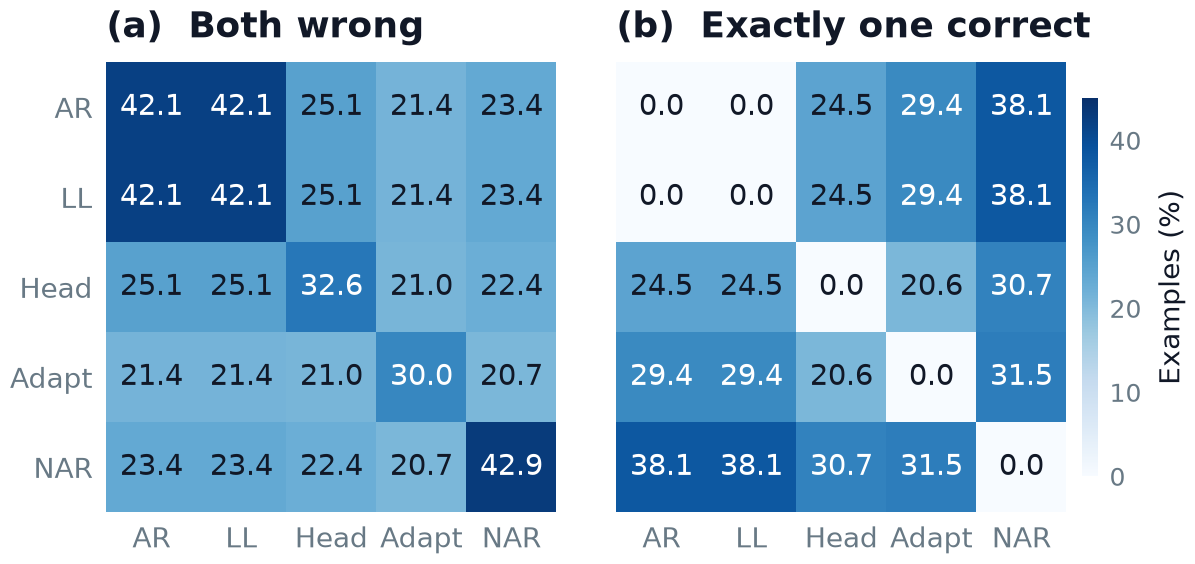

In [53]:
# Pairwise error overlap across the four design families (five implementations).
correct_matrix = np.asarray([
    [FORMULATION_METRICS[name][key]["correct"] for name in FORMULATION_ORDER]
    for key in sorted(reference_keys)
], dtype=bool)
method_labels = [name.replace("Laya-Med", "NAR") for name in FORMULATION_ORDER]
double_fault = np.zeros((len(FORMULATION_ORDER), len(FORMULATION_ORDER)))
complementary = np.zeros_like(double_fault)
error_rows = []
for i, name_i in enumerate(FORMULATION_ORDER):
    for j, name_j in enumerate(FORMULATION_ORDER):
        both_wrong = np.mean(~correct_matrix[:, i] & ~correct_matrix[:, j])
        discordant = np.mean(correct_matrix[:, i] != correct_matrix[:, j])
        double_fault[i, j] = both_wrong
        complementary[i, j] = discordant
        error_rows.append({"method_i": name_i, "method_j": name_j, "n": len(correct_matrix),
                           "both_wrong_pct": 100 * both_wrong,
                           "exactly_one_correct_pct": 100 * discordant})
pd.DataFrame(error_rows).to_csv(PAPER_FIGURES / "four_formulation_error_overlap.csv", index=False)

fig, axes = panel_grid(1, 2, sharey=True, xgap=.6)
shared_vmax = 5 * np.ceil(max(double_fault.max(), complementary.max()) * 100 / 5)
for index, (ax, matrix, title, cmap) in enumerate([
    (axes[0], double_fault * 100, "Both wrong", "Blues"),
    (axes[1], complementary * 100, "Exactly one correct", "Blues"),
]):
    vmax = shared_vmax
    image = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=vmax, aspect="equal")
    ax.set_xticks(range(len(method_labels)), method_labels, rotation=0)
    ax.tick_params(axis="both", labelsize=20)
    ax.set_yticks(range(len(method_labels)), method_labels)
    panel_title(ax, index, title)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(j, i, f"{matrix[i, j]:.1f}", ha="center", va="center", fontsize=ANNOTATION_SIZE, fontweight="normal",
                    color="white" if matrix[i, j] > vmax * .6 else INK)
colorbar = add_colorbar(fig, axes[1], image, label="Examples (%)")
save(fig, "figure3_four_formulation_error_overlap")
plt.show()


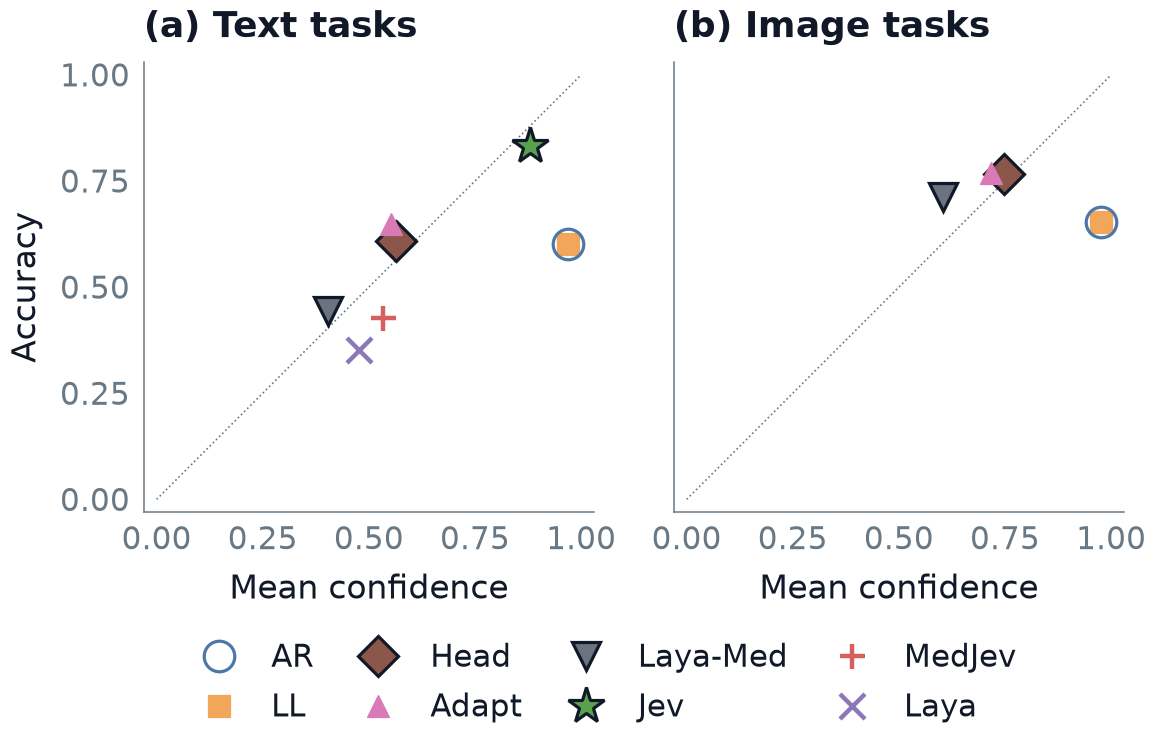

In [54]:
# Mean accuracy vs mean confidence, averaged equally across datasets within each task type.
BASELINE_FILES = {"Jev": ROOT / "results/jev/results.csv", "MedJev": ROOT / "results/medjev/results.csv",
                  "Laya": ROOT / "results/laya/results.csv"}
BASELINE_COLORS = {name: MODEL_COLORS[name] for name in BASELINE_FILES}
ALL_COLORS = {**FORMULATION_COLORS, **BASELINE_COLORS}
TASK_GROUPS = [("Text", TEXT_SET), ("Image", IMAGE_SET)]

summary_rows = []
for method in FORMULATION_ORDER:
    for modality, datasets in TASK_GROUPS:
        per_dataset = []
        for dataset in sorted(datasets):
            entries = [FORMULATION_METRICS[method][key] for key in reference_keys if key[0] == dataset]
            per_dataset.append({"confidence": np.mean([entry["confidence"] for entry in entries]),
                                "accuracy": np.mean([entry["correct"] for entry in entries])})
        summary_rows.append({"method": method, "modality": modality,
                             "confidence": np.mean([row["confidence"] for row in per_dataset]),
                             "accuracy": np.mean([row["accuracy"] for row in per_dataset])})

for method, path in BASELINE_FILES.items():
    table = pd.read_csv(path).drop_duplicates("task").set_index("task")
    for modality, datasets in TASK_GROUPS:
        task_rows = table.loc[table.index.isin(datasets)]
        summary_rows.append({"method": method, "modality": modality,
                             "confidence": task_rows["mean_confidence"].mean(),
                             "accuracy": task_rows["accuracy"].mean()})

summary = pd.DataFrame(summary_rows)
fig, axes = panel_grid(1, 2, legend=True, sharex=True, sharey=True)
for index, (ax, (modality, _)) in enumerate(zip(axes, TASK_GROUPS)):
    ax.plot([0, 1], [0, 1], linestyle=":", color=MUTED, linewidth=1.2, zorder=1)
    subset = summary[summary.modality == modality]
    for row in subset.itertuples():
        if np.isfinite(row.confidence) and np.isfinite(row.accuracy):
            ax.plot(row.confidence, row.accuracy, linestyle="none", label=row.method,
                    zorder=5 if row.method == "AR" else 4,
                    **model_marker(row.method, hollow=row.method == "AR"))
    ax.set(xlim=(-.03, 1.03), ylim=(-.03, 1.03), xlabel="Mean confidence")
    ax.set_xticks([0, .25, .5, .75, 1])
    ax.set_yticks([0, .25, .5, .75, 1])
    ax.set_title(f"({chr(97 + index)}) {modality} tasks", loc="left", pad=18)
axes[0].set_ylabel("Accuracy")
handles, labels = axes[0].get_legend_handles_labels()
figure_legend(fig, handles, labels, ncols=4)
summary.to_csv(PAPER_FIGURES / "all_methods_confidence_accuracy.csv", index=False)
save(fig, "figure4_mean_confidence_accuracy")
plt.show()

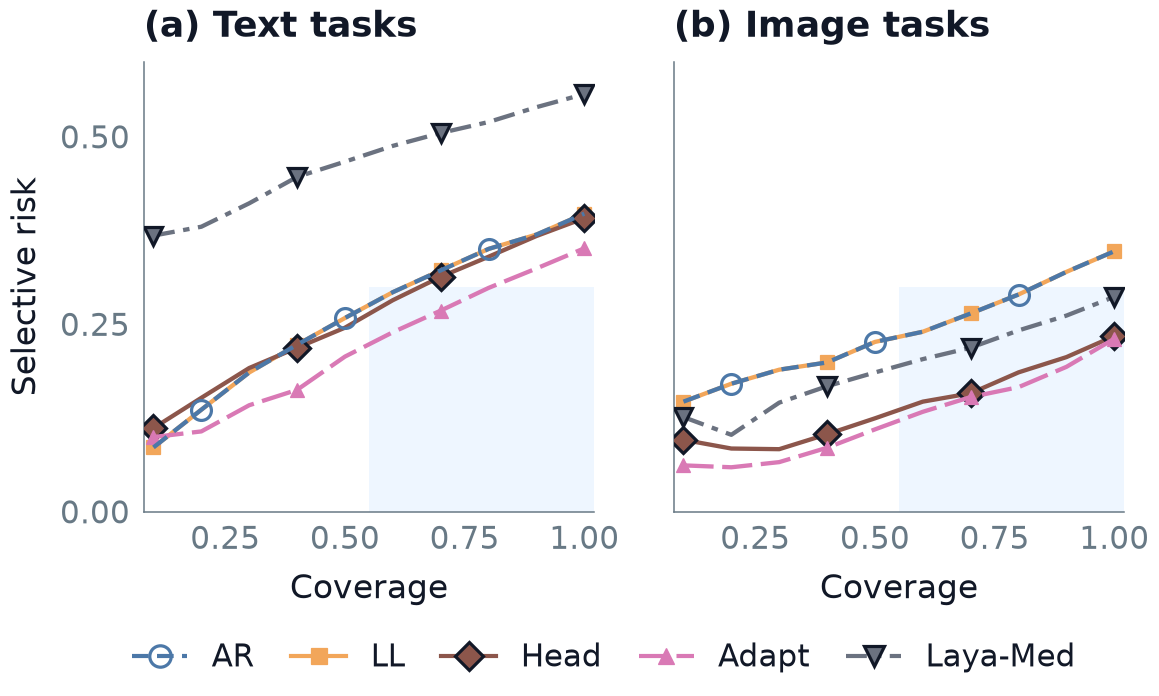

In [55]:
# Confidence-ranked selective risk for all direct-decision formulations, averaged
# equally across datasets in each modality. The dashed AR curve marks its overlap with LL.
coverage_grid = np.linspace(.1, 1.0, 10)
selective_rows = []
fig, axes = panel_grid(1, 2, legend=True, sharey=True)
plotted_risks = []
for index, (ax, modality, datasets) in enumerate([(axes[0], "Text", TEXT_SET), (axes[1], "Image", IMAGE_SET)]):
    prefer(ax, "right", "bottom")
    plot_order = [method for method in FORMULATION_ORDER if method != "AR"] + ["AR"]
    for method in plot_order:
        by_dataset = []
        for dataset in sorted(datasets):
            keys = [key for key in reference_keys if key[0] == dataset]
            ordered = sorted((FORMULATION_METRICS[method][key] for key in keys),
                             key=lambda entry: entry["confidence"], reverse=True)
            curve = []
            for coverage in coverage_grid:
                retained = max(1, int(np.ceil(coverage * len(ordered))))
                risk = 1 - float(np.mean([entry["correct"] for entry in ordered[:retained]]))
                curve.append(risk)
                selective_rows.append({"modality": modality.lower(), "dataset": dataset,
                                       "method": method, "coverage": retained/len(ordered),
                                       "n_retained": retained, "selective_risk": risk})
            by_dataset.append(curve)
        values = np.asarray(by_dataset)
        mean_risk = values.mean(axis=0)
        sem = values.std(axis=0, ddof=1) / np.sqrt(values.shape[0]) if values.shape[0] > 1 else np.zeros_like(mean_risk)
        plotted_risks.extend(mean_risk)
        # Sparse markers and independent line styles separate overlapping curves.
        ax.plot(coverage_grid, mean_risk, linewidth=3.1, color=FORMULATION_COLORS[method], label=method,
                linestyle=MODEL_DASHES[method], markevery=(1 if method == "AR" else 0, 3),
                zorder=5 if method == "AR" else 3,
                **model_marker(method, hollow=method == "AR", scale=.65))
    ax.set(xlabel="Coverage", xlim=(.08, 1.02), ylim=(0, 1))
    ax.set_xticks([.25, .5, .75, 1])
    ax.set_yticks([0, .25, .5, .75, 1])
    ax.set_title(f"({chr(97 + index)}) {modality} tasks", loc="left", pad=18)
axes[0].set_ylabel("Selective risk")
axes[0].set_ylim(*risk_limits(plotted_risks))
handles = [model_handle(m, line=True) for m in FORMULATION_ORDER]
labels = FORMULATION_ORDER
figure_legend(fig, handles, labels, ncols=5)
pd.DataFrame(selective_rows).to_csv(PAPER_FIGURES / "four_formulation_selective_risk.csv", index=False)
save(fig, "figure5_four_formulation_selective_risk")
save(fig, "posthoc_risk_coverage_all_formulations")
plt.show()

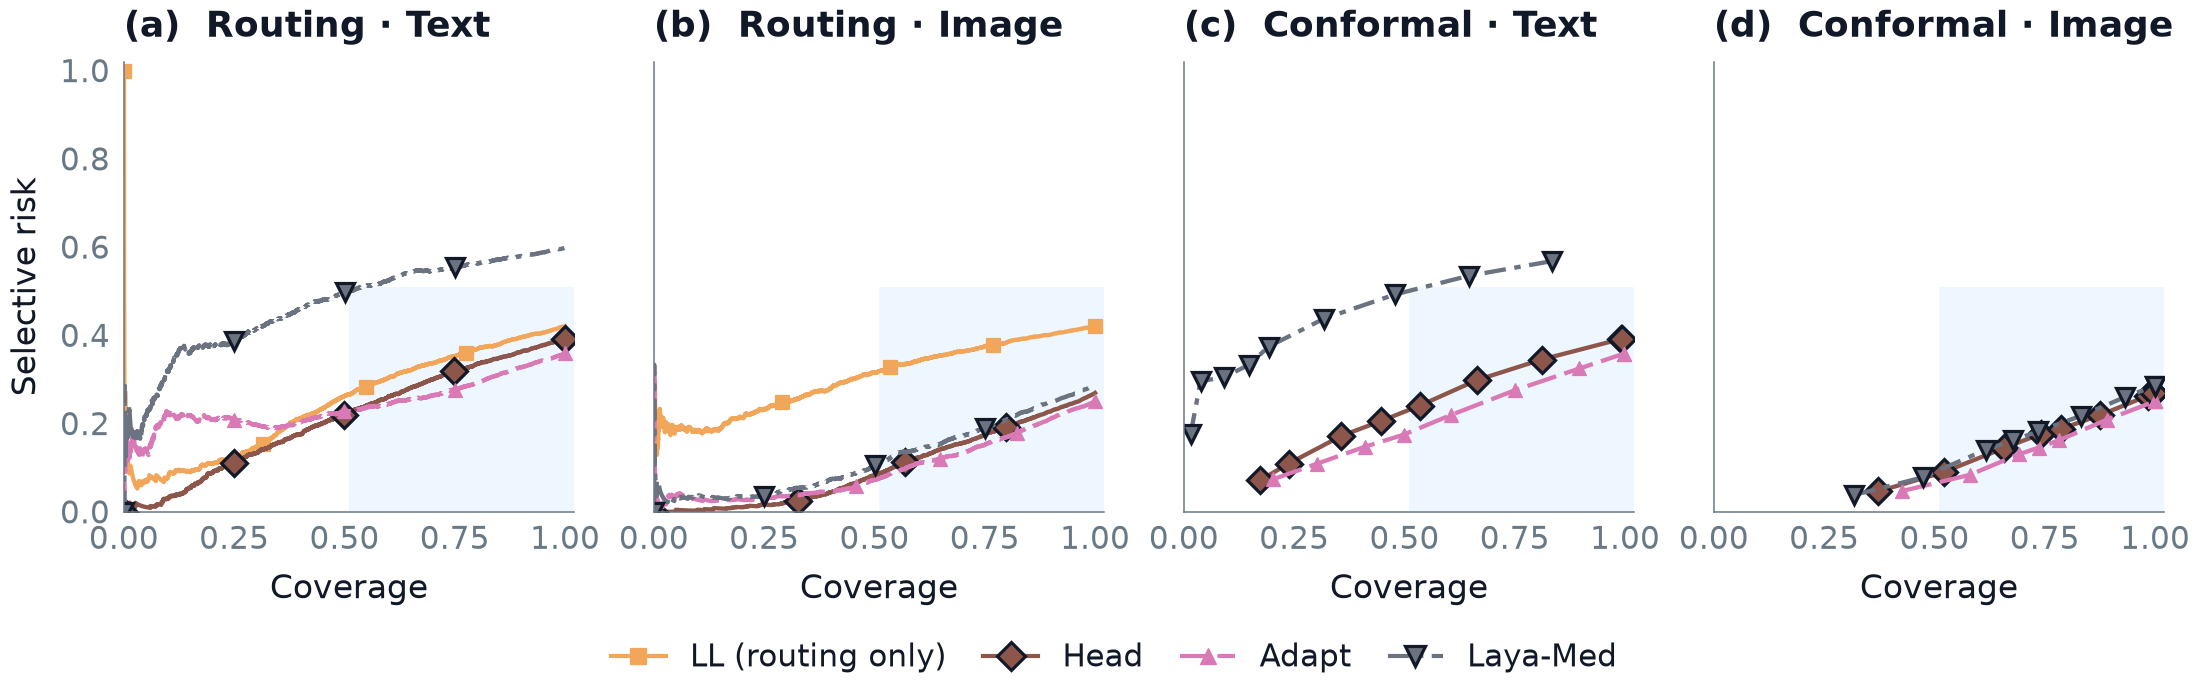

In [56]:
# Compare confidence-threshold routing and per-dataset split conformal.
# LL has no designated calibration export: show routing only, never calibrate on test rows.
# Both axes pool the same modality cohort: risk = accepted errors / accepted count.
from collections import defaultdict

POLICY_METHODS = ["LL", "Head", "Adapt", "Laya-Med"]
CALIBRATION_FILES = {"Head": RESULTS / "medgemma-head/calibration.predictions.jsonl",
                     "Adapt": RESULTS / "medgemma-lora/calibration.predictions.jsonl",
                     "Laya-Med": RESULTS / "laya/correct-calibration.predictions.jsonl"}
ALPHAS = [.02, .05, .1, .15, .2, .3, .4, .5, .6]

def conformal_quantile(scores, alpha):
    if len(scores) == 0:
        raise ValueError("Missing calibration scores")
    rank = int(np.ceil((len(scores) + 1) * (1 - alpha)))
    return np.inf if rank > len(scores) else float(np.sort(scores)[rank - 1])

policy_rows = []
for method in POLICY_METHODS:
    scores = defaultdict(list)
    if method in CALIBRATION_FILES:
        calibration = read_jsonl(CALIBRATION_FILES[method])
        cal_keys = [(r.get("dataset", r.get("task")), str(r["id"])) for r in calibration]
        if len(cal_keys) != len(set(cal_keys)) or set(cal_keys) & reference_keys:
            raise ValueError(f"{method}: duplicate calibration IDs or calibration/test overlap")
        for row, (dataset, _) in zip(calibration, cal_keys):
            p = _row_probabilities(row)
            scores[dataset].append(p.max() - p[int(row["label"])])
        if not set(DATASET_ORDER) <= set(scores):
            raise ValueError(f"{method}: incomplete calibration datasets")
    for modality, datasets in (("Text", TEXT_SET), ("Image", IMAGE_SET)):
        keys = [key for key in sorted(reference_keys) if key[0] in datasets]
        confidence = np.asarray([FORMULATION_METRICS[method][key]["confidence"] for key in keys])
        correct = np.asarray([FORMULATION_METRICS[method][key]["correct"] for key in keys])
        n = len(keys)
        # Actual thresholds retain confidence ties together, without arbitrary prefix ordering.
        for tau in np.unique(confidence):
            accepted = confidence >= tau
            count = int(accepted.sum())
            errors = int((~correct[accepted]).sum())
            policy_rows.append(dict(method=method, modality=modality, policy="Routing",
                                    parameter=float(tau), n=n, accepted_n=count, error_n=errors,
                                    coverage=count/n, risk=errors/count))
        if method not in CALIBRATION_FILES:
            continue
        for alpha in ALPHAS:
            thresholds = {d: conformal_quantile(np.asarray(scores[d]), alpha) for d in datasets}
            count = errors = 0
            for key in keys:
                row = FORMULATION_INDEX[method][key]
                p = _row_probabilities(row)
                selected = np.flatnonzero(p.max() - p <= thresholds[key[0]])
                if len(selected) == 1:
                    count += 1
                    errors += int(selected[0] != int(row["label"]))
            policy_rows.append(dict(method=method, modality=modality, policy="Conformal",
                                    parameter=alpha, n=n, accepted_n=count, error_n=errors,
                                    coverage=count/n, risk=errors/count if count else np.nan))
policy_frame = pd.DataFrame(policy_rows)
policy_frame.to_csv(PAPER_FIGURES / "posthoc_policy_risk_coverage.csv", index=False)

panels = [("Routing", "Text"), ("Routing", "Image"),
          ("Conformal", "Text"), ("Conformal", "Image")]
fig, axes = panel_grid(1, 4, legend=True, sharex=True, sharey=True)
for index, (ax, (policy, modality)) in enumerate(zip(axes.flat, panels)):
    prefer(ax, "right", "bottom")
    for method in POLICY_METHODS:
        subset = policy_frame[(policy_frame.modality == modality) & (policy_frame.method == method)
                              & (policy_frame.policy == policy)].dropna(subset=["risk"]).sort_values("coverage")
        style = model_marker(method, scale=.65)
        markevery = 1 if policy == "Conformal" else max(1, len(subset) // 4)
        ax.plot(subset.coverage, subset.risk, color=FORMULATION_COLORS[method], linewidth=3.1,
                linestyle=MODEL_DASHES[method], markevery=markevery, **style)
    ax.set(xlim=(0, 1.02), ylim=risk_limits(policy_frame.risk))
    ax.set_xticks([0, .25, .5, .75, 1])
    ax.set_yticks(np.arange(0, risk_limits(policy_frame.risk)[1] + .001, .2))
    ax.set_title(f"({chr(97 + index)})  {policy} · {modality}", loc="left", pad=18)
    ax.set_xlabel("Coverage")
    if index == 0:
        ax.set_ylabel("Selective risk")
handles = [model_handle(m, line=True) for m in POLICY_METHODS]
figure_legend(fig, handles, ["LL (routing only)", "Head", "Adapt", "Laya-Med"], ncols=4)
save(fig, "posthoc_risk_coverage_policies")
plt.show()
